## Step 0 — Setup and Dataset Validation

## Objective

Initialize Python environment and verify dataset files, spectral dimensions, segmentation masks, and nitrogen treatment labels.

## Rationale

Ensures data exists and matches expected structure before computation, visualization, or ML modeling.

## Key Operations

* Import numerical, statistical, and image processing libraries
* Define directories for hyperspectral cubes and segmentation masks
* Load nitrogen treatment metadata into a table
* Print data shape, sample metadata, and available segmentation regions

## Expected Outcome

Confirms valid file paths, correct image dimensions, readable labels, and balanced nitrogen classes for logical continuation.


In [1]:
# Step 0: Import libraries and inspect available data

import os
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

# ---- Paths (adjust if your folders are named differently) ----
RAW_DIR = "/Users/souravranjanmohapatra/Downloads/Phenotyping_project/CornHSI/raw_data"      # folder containing .npz hyperspectral files
SEG_DIR = "/Users/souravranjanmohapatra/Downloads/Phenotyping_project/CornHSI/seg_data"      # folder containing segmentation masks (.gif)
GT_FILE = "/Users/souravranjanmohapatra/Downloads/Phenotyping_project/CornHSI/groundtruth.xlsx"  # metadata file

# ---- Load ground truth table ----
gt = pd.read_excel(GT_FILE)
print("✅ Loaded groundtruth.xlsx")
print("Shape:", gt.shape)
print(gt.head())

# ---- List raw hyperspectral files ----
raw_files = sorted(glob.glob(os.path.join(RAW_DIR, "*.npz")))
seg_files = sorted(glob.glob(os.path.join(SEG_DIR, "*.gif")))

print("\nNumber of raw hyperspectral files (.npz):", len(raw_files))
print("Example raw file:", raw_files[0] if raw_files else "None found")

print("\nNumber of segmentation mask files (.gif):", len(seg_files))
print("Example seg file:", seg_files[0] if seg_files else "None found")

# ---- Quick check: treatments in ground truth ----
if 'treatment' in gt.columns:
    print("\nUnique treatments in groundtruth:")
    print(gt['treatment'].value_counts())
else:
    print("\nColumn 'treatment' not found in groundtruth.xlsx columns:")
    print(gt.columns.tolist())


✅ Loaded groundtruth.xlsx
Shape: (40, 4)
                                           file_name genotype treatment     N
0  22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-4...  P1105AM        N1  3.00
1  22fieldcorn01fday2_4_2_na_1_2021-04-21-15-57-4...  P1105AM        N1  3.00
2  22fieldcorn01fday2_4_3_na_1_2021-04-21-15-58-4...  P1105AM        N1  3.00
3  22fieldcorn01fday2_4_1_na_2_2021-04-21-15-53-3...  P1105AM        N1  2.96
4  22fieldcorn01fday2_4_2_na_2_2021-04-21-15-54-3...  P1105AM        N1  2.96

Number of raw hyperspectral files (.npz): 40
Example raw file: /Users/souravranjanmohapatra/Downloads/Phenotyping_project/CornHSI/raw_data/22fieldcorn01fday2_14_1_na_1_2021-04-21-17-01-47_11-25-2021_15-58-35.npz

Number of segmentation mask files (.gif): 40
Example seg file: /Users/souravranjanmohapatra/Downloads/Phenotyping_project/CornHSI/seg_data/22fieldcorn01fday2_14_1_na_1_2021-04-21-17-01-47_11-25-2021_15-58-35.gif

Unique treatments in groundtruth:
treatment
N1    20
N2    20
Na

## Step 1 — Load a Hyperspectral Leaf Cube

## Objective

Load one hyperspectral corn leaf data cube from file and inspect its dimensions.

## Rationale

Understanding the original data format and spectral band count is necessary before applying transformations such as scaling, index computation, or machine learning.

## Key Operations

Load a single NPZ file into memory
Store spectral reflectance matrix and wavelength bands
Print cube shape to verify spatial and spectral resolution

## Expected Outcome

Returns the hyperspectral cube dimensions (Height, Width, Number of Bands)
Confirms that the file is readable and correctly structured


Using example leaf: 22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-46_11-25-2021_14-53-36
Raw path: /Users/souravranjanmohapatra/Downloads/Phenotyping_project/CornHSI/raw_data/22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-46_11-25-2021_14-53-36.npz
Seg path: /Users/souravranjanmohapatra/Downloads/Phenotyping_project/CornHSI/seg_data/22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-46_11-25-2021_14-53-36.npz

Keys in raw_data: ['arr_0']
Keys in seg_data: ['leaf_mask', 'vein_mask', 'mrib_mask', 'meso_mask', 'leaf_edge_mask', 'leaf_tip_mask', 'cln_leaf_mask']

raw_img shape: (224, 1111, 364)
leaf_mask shape: (224, 1111)


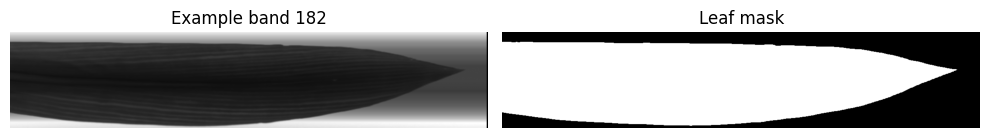

In [2]:
# Step 1: Load ONE example leaf (raw hyperspectral cube + segmentation mask)
import numpy as np
import matplotlib.pyplot as plt
import os

# 1) Pick one example file name from groundtruth
example_name = gt['file_name'].iloc[0]   # you can change index 0 → 1,2,... later
print("Using example leaf:", example_name)

# 2) Build paths for raw and segmented data (.npz)
raw_path = os.path.join(RAW_DIR, example_name + ".npz")
seg_path = os.path.join(SEG_DIR, example_name + ".npz")   # segmentation is stored as npz in the demo

print("Raw path:", raw_path)
print("Seg path:", seg_path)

# 3) Load the npz files
raw_data = np.load(raw_path)
seg_data = np.load(seg_path)

print("\nKeys in raw_data:", raw_data.files)
print("Keys in seg_data:", seg_data.files)

# 4) Extract the main arrays
#    In the demo, the hyperspectral cube is saved under 'arr_0'
raw_img = raw_data[raw_data.files[0]]      # shape: (H, W, Bands)
leaf_mask = seg_data[seg_data.files[0]]    # shape: (H, W) – boolean or 0/1

print("\nraw_img shape:", raw_img.shape)
print("leaf_mask shape:", leaf_mask.shape)

# 5) Visualize: one spectral band + the mask
band_idx = raw_img.shape[2] // 2  # just pick a middle band for now

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(raw_img[:, :, band_idx], cmap='gray')
axes[0].set_title(f"Example band {band_idx}")
axes[0].axis('off')

axes[1].imshow(leaf_mask, cmap='gray')
axes[1].set_title("Leaf mask")
axes[1].axis('off')

plt.tight_layout()
plt.show()


## Step 2 — Apply Leaf Mask and Compute Whole-Leaf Spectrum

## Objective

Isolate leaf pixels using the segmentation mask and compute the mean and variability of the reflectance spectrum for the entire leaf.

## Rationale

Background pixels (tray, sensor, noise) should not influence spectral analysis. By applying the leaf mask, we restrict calculations to true leaf tissue. The mean spectrum across all leaf pixels provides a compact and representative spectral signature for that leaf, and the standard deviation shows how much variation exists within the leaf.

## Key Operations

Convert the raw leaf mask into a boolean array indicating which pixels belong to the leaf.
Use boolean indexing on the hyperspectral cube to extract a matrix of shape (number of leaf pixels, number of bands).
Compute the mean reflectance and standard deviation at each band across all leaf pixels.
Plot the mean spectrum as a line with a shaded band representing ±1 standard deviation, using band index on the x-axis.

## Expected Outcome

Printed counts of leaf pixels and the shape of the leaf pixel matrix.
A plot showing the overall leaf reflectance spectrum with variability, confirming that the leaf spectra are reasonable before any wavelength mapping or index computation.

Leaf pixels: 161904
leaf_pixels shape: (161904, 364)
Number of spectral bands: 364


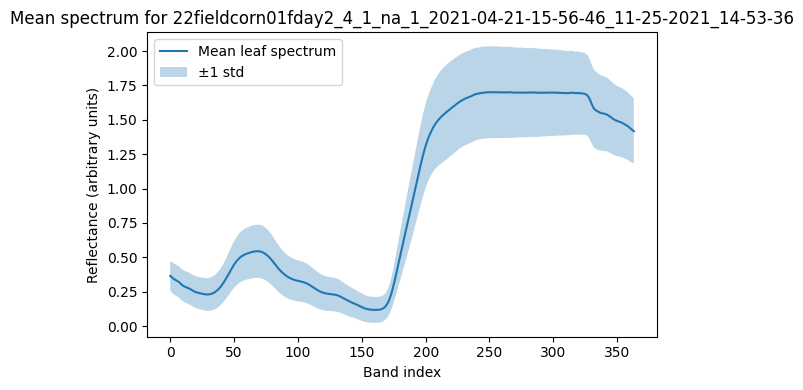

In [3]:
# Step 2: Apply the leaf mask and compute mean spectrum for this leaf

import numpy as np
import matplotlib.pyplot as plt

# 1) Ensure mask is boolean
leaf_mask_bool = leaf_mask > 0

print("Leaf pixels:", leaf_mask_bool.sum())

# 2) Extract leaf pixels: shape → (num_pixels, num_bands)
leaf_pixels = raw_img[leaf_mask_bool]   # uses boolean indexing
print("leaf_pixels shape:", leaf_pixels.shape)  # (N_pixels, N_bands)

# 3) Compute mean and std spectrum over all leaf pixels
mean_spectrum = leaf_pixels.mean(axis=0)
std_spectrum  = leaf_pixels.std(axis=0)

print("Number of spectral bands:", mean_spectrum.shape[0])

# 4) Plot the mean spectrum (band index on x-axis for now)
bands = np.arange(mean_spectrum.shape[0])

plt.figure(figsize=(6,4))
plt.plot(bands, mean_spectrum, label='Mean leaf spectrum')
plt.fill_between(bands,
                 mean_spectrum - std_spectrum,
                 mean_spectrum + std_spectrum,
                 alpha=0.3,
                 label='±1 std')
plt.xlabel("Band index")
plt.ylabel("Reflectance (arbitrary units)")
plt.title(f"Mean spectrum for {example_name}")
plt.legend()
plt.tight_layout()
plt.show()


## Step 3 — Wavelength Calibration and Spectrum Replot

## Objective

Convert spectral band indices into physical wavelengths (nanometers) and replot the whole-leaf mean spectrum against wavelength instead of raw band index.

## Rationale

Physiological interpretation of nitrogen stress depends on knowing which part of the spectrum corresponds to chlorophyll absorption and the red-edge region. Wavelength calibration ensures the plots and models align with real optical properties rather than arbitrary band positions.

## Key Operations

* Define calibration coefficients from the imaging system used in the professor’s reference workflow.
* Create a function that maps band index → wavelength (nm) using the formula ( \lambda = (b + 50) \cdot 1.3330 + 461.7562 ).
* Generate a wavelength vector for all spectral bands.
* Print the spectral resolution and wavelength span.
* Plot mean ± 1 standard-deviation spectrum versus wavelength.

## Expected Outcome

* Confirms that the spectral axis is successfully converted to nm units.
* Produces a biologically interpretable reflectance curve, enabling discussion of nitrogen-related effects near chlorophyll-sensitive wavelengths.


Number of bands: 364
Wavelength range: 528.4 nm to 1012.3 nm


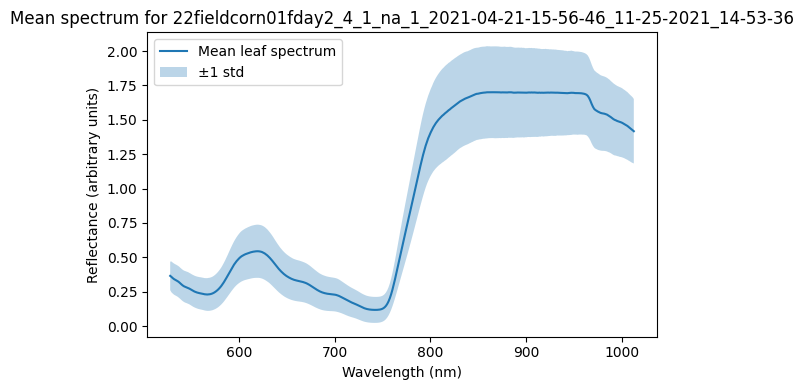

In [4]:
# Step 3: Map band index to wavelength (nm) and replot the spectrum

import numpy as np
import matplotlib.pyplot as plt

# 1) Wavelength mapping (same as in the demo notebook)
pst2wv_coe = [1.3330, 461.7562]

def band_to_wavelength(band_index):
    """
    Map spectral band index to wavelength (nm).
    Formula comes from the camera calibration used in the demo.
    """
    return (band_index + 50) * pst2wv_coe[0] + pst2wv_coe[1]

# 2) Build wavelength array for all bands in this image
num_bands = raw_img.shape[2]
wavelengths = np.array([band_to_wavelength(i) for i in range(num_bands)])

print("Number of bands:", num_bands)
print("Wavelength range: {:.1f} nm to {:.1f} nm".format(wavelengths.min(), wavelengths.max()))

# 3) Plot mean spectrum vs wavelength
plt.figure(figsize=(6,4))
plt.plot(wavelengths, mean_spectrum, label='Mean leaf spectrum')
plt.fill_between(wavelengths,
                 mean_spectrum - std_spectrum,
                 mean_spectrum + std_spectrum,
                 alpha=0.3,
                 label='±1 std')
plt.xlabel("Wavelength (nm)")
plt.ylabel("Reflectance (arbitrary units)")
plt.title(f"Mean spectrum for {example_name}")
plt.legend()
plt.tight_layout()
plt.show()


## Step 4 — Compute NDVI and OCAR Index Maps for One Leaf

## Objective

Compute two vegetation indices (NDVI and OCAR) from selected hyperspectral bands for the current leaf and visualize their spatial distribution over the leaf area.

## Rationale

NDVI and OCAR are simple but powerful indicators of chlorophyll content and canopy vigor. Calculating these indices at the pixel level and summarizing them over the leaf provides an interpretable link between hyperspectral reflectance and nitrogen status. This also creates index maps that will later be summarized at leaf and region levels.

## Key Operations

Define a helper function to find the band index closest to a target wavelength (630 nm, 680 nm, 800 nm) using the calibrated wavelength array.
Select the red, NIR, and orange band images by index.
Compute NDVI using (NIR − Red) / (NIR + Red) and OCAR using (Orange − Red) / (Orange + Red) with a small epsilon to avoid division by zero.
Apply the leaf mask to create NaN-masked NDVI and OCAR maps so background is excluded in visualization.
Compute mean NDVI and mean OCAR over all leaf pixels.
Plot red band, NIR band, NDVI map, and OCAR map side by side for visual inspection.

## Expected Outcome

Printed indices showing the average NDVI and OCAR values for the leaf.
Visual maps that highlight how these indices vary spatially across the leaf surface, confirming that higher values correspond to expected healthy regions.

Red band index (for ~680 nm):    114 actual: 680.3682
NIR band index (for ~800 nm):    204 actual: 800.3381999999999
Orange band index (for ~630 nm): 76 actual: 629.7142

Mean NDVI over leaf:  0.691
Mean OCAR over leaf:  0.325


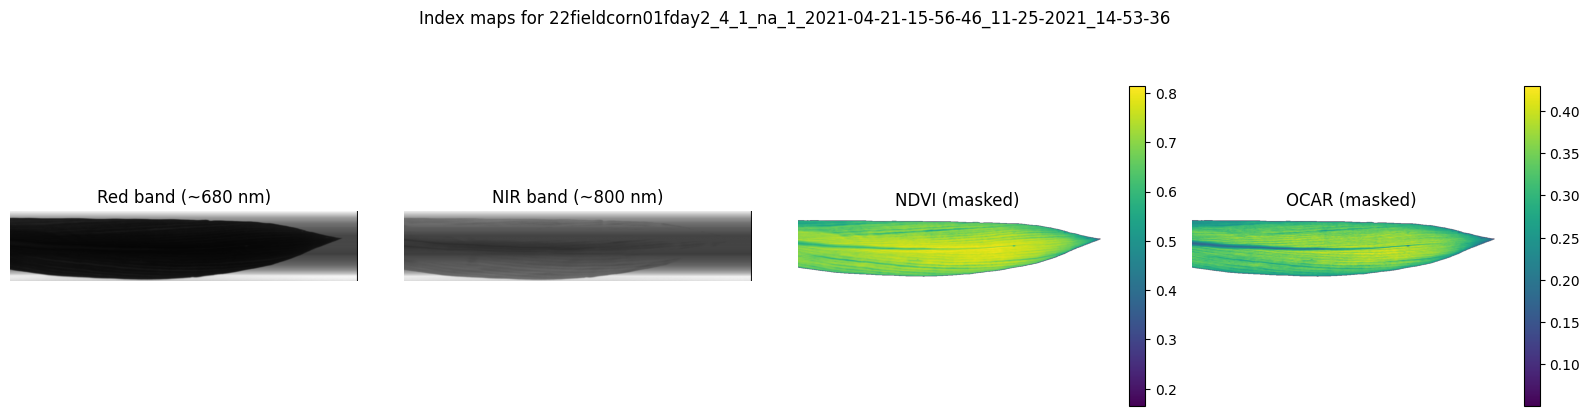

In [5]:
# Step 4: Compute NDVI and OCAR (Orange/Red Chlorophyll Absorption Ratio) for this leaf

import numpy as np
import matplotlib.pyplot as plt

# Helper: find the band index closest to a target wavelength (nm)
def find_band_for_wavelength(target_nm, wv_array):
    return int(np.argmin(np.abs(wv_array - target_nm)))

# Target wavelengths (approximate)
RED_NM    = 680   # red for NDVI and OCAR
NIR_NM    = 800   # NIR for NDVI
ORANGE_NM = 630   # orange for OCAR

# Find closest band indices
red_idx    = find_band_for_wavelength(RED_NM, wavelengths)
nir_idx    = find_band_for_wavelength(NIR_NM, wavelengths)
orange_idx = find_band_for_wavelength(ORANGE_NM, wavelengths)

print("Red band index (for ~680 nm):   ", red_idx,    "actual:", wavelengths[red_idx])
print("NIR band index (for ~800 nm):   ", nir_idx,    "actual:", wavelengths[nir_idx])
print("Orange band index (for ~630 nm):", orange_idx, "actual:", wavelengths[orange_idx])

# Extract the single-band images (convert to float)
red_img    = raw_img[:, :, red_idx].astype(float)
nir_img    = raw_img[:, :, nir_idx].astype(float)
orange_img = raw_img[:, :, orange_idx].astype(float)

# Small epsilon to avoid division by zero
eps = 1e-8

# NDVI = (NIR - Red) / (NIR + Red)
ndvi = (nir_img - red_img) / (nir_img + red_img + eps)

# OCAR = (Orange - Red) / (Orange + Red)   (same NDVI formula but with 630 and 680 nm)
ocar = (orange_img - red_img) / (orange_img + red_img + eps)

# Masked versions for visualization (background as NaN)
ndvi_plot = np.where(leaf_mask_bool, ndvi, np.nan)
ocar_plot = np.where(leaf_mask_bool, ocar, np.nan)

# Compute mean NDVI and OCAR over the leaf
mean_ndvi = ndvi[leaf_mask_bool].mean()
mean_ocar = ocar[leaf_mask_bool].mean()

print(f"\nMean NDVI over leaf:  {mean_ndvi:.3f}")
print(f"Mean OCAR over leaf:  {mean_ocar:.3f}")

# Visualize the maps
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(red_img, cmap='gray')
axes[0].set_title(f"Red band (~{wavelengths[red_idx]:.0f} nm)")
axes[0].axis('off')

axes[1].imshow(nir_img, cmap='gray')
axes[1].set_title(f"NIR band (~{wavelengths[nir_idx]:.0f} nm)")
axes[1].axis('off')

im2 = axes[2].imshow(ndvi_plot, cmap='viridis')
axes[2].set_title("NDVI (masked)")
axes[2].axis('off')
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

im3 = axes[3].imshow(ocar_plot, cmap='viridis')
axes[3].set_title("OCAR (masked)")
axes[3].axis('off')
plt.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

plt.suptitle(f"Index maps for {example_name}", y=1.05, fontsize=12)
plt.tight_layout()
plt.show()


## Step 6 - Leaf-Level Feature Table for All Leaves

## Objective

Build a compact feature table where each row corresponds to one leaf and contains summary spectral features and indices useful for nitrogen classification.

## Rationale

To compare N1 and N2 treatments statistically or with machine-learning models, we need a consistent set of features computed for every leaf. Whole-leaf NDVI, whole-leaf OCAR, and selected reflectance values at key wavelengths provide a simple yet informative descriptor of nitrogen status.

## What this cell does

* Iterates over all leaves listed in the metadata table
* Loads each hyperspectral cube and corresponding segmentation mask
* Ensures a consistent wavelength axis for all cubes
* Computes whole-leaf NDVI and OCAR using the leaf mask
* Computes the mean reflectance spectrum over all leaf pixels
* Samples reflectance at selected wavelengths (e.g. 550, 680, 800 nm)
* Stores these values into a feature row for each leaf and assembles a DataFrame

## Expected output

* A DataFrame named `feature_table` with one row per leaf
* Columns including:

  * `file_name`, `treatment`
  * `mean_ndvi_leaf`, `mean_ocar_leaf`
  * Reflectance features such as `refl_550nm`, `refl_680nm`, `refl_800nm`
* Printed shape of the table and a preview of the first few rows

In [6]:
# Step 6: Loop over ALL leaves and build a leaf-level feature table
import numpy as np
import pandas as pd
import os

feature_rows = []

# Reuse band_to_wavelength() and find_band_for_wavelength() from earlier
# If wavelengths_global is not defined yet, compute it from the first file.
wavelengths_global = None

for idx, row in gt.iterrows():
    file_name = row["file_name"]
    treatment = row.get("treatment", None)

    raw_path = os.path.join(RAW_DIR, file_name + ".npz")
    seg_path = os.path.join(SEG_DIR, file_name + ".npz")

    if not (os.path.exists(raw_path) and os.path.exists(seg_path)):
        print(f"Skipping {file_name}: raw or seg file not found.")
        continue

    # ---- Load data ----
    raw_data = np.load(raw_path)
    seg_data = np.load(seg_path)

    raw_img_i = raw_data[raw_data.files[0]]       # (H, W, Bands)
    leaf_mask_i = seg_data["leaf_mask"]          # assume this key exists
    leaf_mask_bool_i = leaf_mask_i > 0

    # Skip if no leaf pixels
    if leaf_mask_bool_i.sum() == 0:
        print(f"Skipping {file_name}: no leaf pixels in mask.")
        continue

    # ---- Wavelengths (compute once globally) ----
    if wavelengths_global is None:
        num_bands_i = raw_img_i.shape[2]
        wavelengths_global = np.array(
            [band_to_wavelength(b) for b in range(num_bands_i)]
        )
        print("Initialized global wavelength array with",
              num_bands_i, "bands.")
    else:
        num_bands_i = raw_img_i.shape[2]
        if num_bands_i != len(wavelengths_global):
            print(f"Skipping {file_name}: number of bands ({num_bands_i}) "
                  f"differs from global ({len(wavelengths_global)}).")
            continue

    # ---- Compute NDVI & OCAR for the whole leaf ----
    red_idx    = find_band_for_wavelength(RED_NM,    wavelengths_global)
    nir_idx    = find_band_for_wavelength(NIR_NM,    wavelengths_global)
    orange_idx = find_band_for_wavelength(ORANGE_NM, wavelengths_global)

    red_img_i    = raw_img_i[:, :, red_idx].astype(float)
    nir_img_i    = raw_img_i[:, :, nir_idx].astype(float)
    orange_img_i = raw_img_i[:, :, orange_idx].astype(float)

    eps = 1e-8
    ndvi_i = (nir_img_i - red_img_i) / (nir_img_i + red_img_i + eps)
    ocar_i = (orange_img_i - red_img_i) / (orange_img_i + orange_img_i + eps)

    # Whole-leaf means
    mean_ndvi_leaf = ndvi_i[leaf_mask_bool_i].mean()
    mean_ocar_leaf = ocar_i[leaf_mask_bool_i].mean()

    # ---- Example reflectance features at key wavelengths ----
    sample_wvs = [550, 680, 800]
    reflectance_features = {}

    leaf_pixels_i = raw_img_i[leaf_mask_bool_i]   # (N_pixels, N_bands)
    mean_spectrum_i = leaf_pixels_i.mean(axis=0)  # (N_bands,)

    for wv in sample_wvs:
        b_idx = find_band_for_wavelength(wv, wavelengths_global)
        reflectance_features[f"refl_{int(wv)}nm"] = mean_spectrum_i[b_idx]

    # ---- Build one feature row for this leaf ----
    feat_row = {
        "file_name": file_name,
        "treatment": treatment,
        "mean_ndvi_leaf": mean_ndvi_leaf,
        "mean_ocar_leaf": mean_ocar_leaf,
    }

    # Add reflectance features
    feat_row.update(reflectance_features)

    feature_rows.append(feat_row)

# ---- Build feature table DataFrame ----
feature_table = pd.DataFrame(feature_rows)
print("\nBuilt leaf-level feature table.")
print("Shape:", feature_table.shape)
feature_table.head()


Initialized global wavelength array with 364 bands.

Built leaf-level feature table.
Shape: (40, 7)


,file_name,treatment,mean_ndvi_leaf,mean_ocar_leaf,refl_550nm,refl_680nm,refl_800nm
0,22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-4...,N1,0.691367,0.244532,0.267007,0.269239,1.408893
1,22fieldcorn01fday2_4_2_na_1_2021-04-21-15-57-4...,N1,0.783000,0.261719,0.264423,0.160427,1.264816
2,22fieldcorn01fday2_4_3_na_1_2021-04-21-15-58-4...,N1,0.783749,0.259463,0.250563,0.156097,1.226135
3,22fieldcorn01fday2_4_1_na_2_2021-04-21-15-53-3...,N1,0.716784,0.250067,0.258377,0.232647,1.355301
4,22fieldcorn01fday2_4_2_na_2_2021-04-21-15-54-3...,N1,0.776546,0.259444,0.264291,0.170545,1.314709


## Step 7 — N1 vs N2 Comparison using Leaf-Level Features

## Objective

Compare low-nitrogen (N1) and high-nitrogen (N2) leaves using whole-leaf indices and reflectance features through boxplots and simple statistical tests.

## Rationale

To quantify how nitrogen treatment affects hyperspectral characteristics, it is necessary to assess whether summary features such as mean NDVI, mean OCAR, and reflectance at key wavelengths differ significantly between N1 and N2 groups. Boxplots provide visual separation, and t-tests provide quantitative evidence.

## What this cell does

Checks that the treatment column is present in the feature table.
Splits the leaf feature table into two groups based on treatment (N1 and N2).
Defines a helper function that:
draws a boxplot comparing N1 vs N2 for a selected feature
runs a Welch t-test between groups and prints the t-statistic and p-value
Applies this helper to:
mean_ndvi_leaf
mean_ocar_leaf
refl_550nm, refl_680nm, refl_800nm

## Expected output

Group sizes for N1 and N2 leaves.
Boxplots showing the distribution of each feature for N1 vs N2.
Printed t-statistics and p-values indicating whether differences between nitrogen treatments are statistically significant for each feature.

Group sizes: 20 N1 leaves, 20 N2 leaves

Whole-leaf indices



/var/folders/m3/dmdf9gcd7l1bdgq8whr7kbjr0000gn/T/ipykernel_69837/2536870128.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


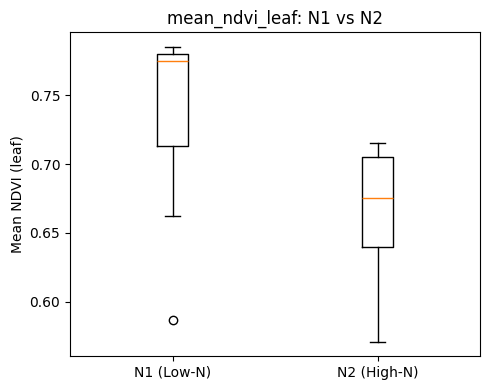

t-test for mean_ndvi_leaf: t = 4.972, p = 0.0000
------------------------------------------------------



/var/folders/m3/dmdf9gcd7l1bdgq8whr7kbjr0000gn/T/ipykernel_69837/2536870128.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


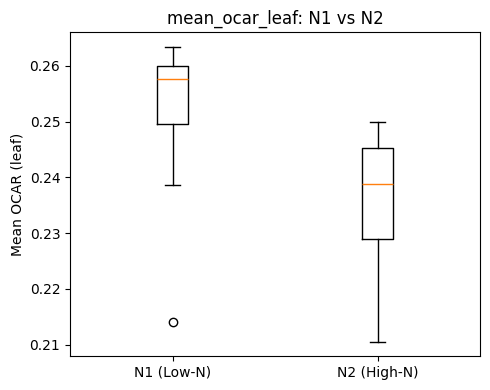

t-test for mean_ocar_leaf: t = 4.837, p = 0.0000
------------------------------------------------------

Reflectance features at key wavelengths



/var/folders/m3/dmdf9gcd7l1bdgq8whr7kbjr0000gn/T/ipykernel_69837/2536870128.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


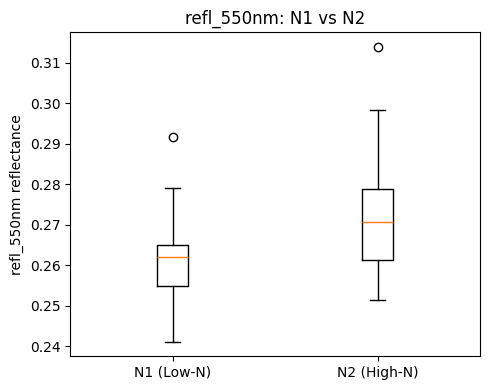

t-test for refl_550nm: t = -2.353, p = 0.0241
------------------------------------------------------



/var/folders/m3/dmdf9gcd7l1bdgq8whr7kbjr0000gn/T/ipykernel_69837/2536870128.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


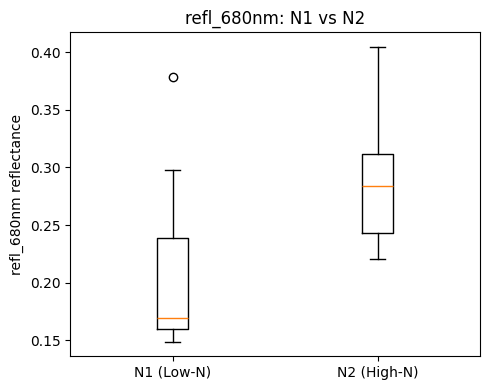

t-test for refl_680nm: t = -4.619, p = 0.0000
------------------------------------------------------



/var/folders/m3/dmdf9gcd7l1bdgq8whr7kbjr0000gn/T/ipykernel_69837/2536870128.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


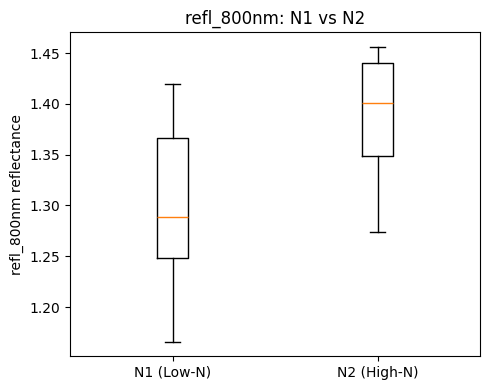

t-test for refl_800nm: t = -3.975, p = 0.0004
------------------------------------------------------



In [7]:
# Step 7: Compare N1 vs N2 using boxplots and simple statistics

import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

# Ensure treatment column exists
if "treatment" not in feature_table.columns:
    raise ValueError("Column 'treatment' not found in feature_table")

# Split groups
group_N1 = feature_table[feature_table["treatment"] == "N1"]
group_N2 = feature_table[feature_table["treatment"] == "N2"]

print("Group sizes:", len(group_N1), "N1 leaves,", len(group_N2), "N2 leaves\n")

# Helper function to do boxplot + t-test
def boxplot_and_ttest(feature_name, ylabel=None):
    data_N1 = group_N1[feature_name].dropna()
    data_N2 = group_N2[feature_name].dropna()

    plt.figure(figsize=(5, 4))
    plt.boxplot(
        [data_N1, data_N2],
        labels=["N1 (Low-N)", "N2 (High-N)"]
    )
    plt.title(f"{feature_name}: N1 vs N2")
    plt.ylabel(ylabel if ylabel else feature_name)
    plt.tight_layout()
    plt.show()

    # Welch t-test
    t, p = ttest_ind(data_N1, data_N2, equal_var=False)
    print(f"t-test for {feature_name}: t = {t:.3f}, p = {p:.4f}")
    print("------------------------------------------------------\n")

print("Whole-leaf indices\n")

# Whole-leaf NDVI and OCAR
boxplot_and_ttest("mean_ndvi_leaf", ylabel="Mean NDVI (leaf)")
boxplot_and_ttest("mean_ocar_leaf", ylabel="Mean OCAR (leaf)")

print("Reflectance features at key wavelengths\n")

# Reflectance at selected wavelengths
for feat in ["refl_550nm", "refl_680nm", "refl_800nm"]:
    boxplot_and_ttest(feat, ylabel=f"{feat} reflectance")


## Step 8 - Leaf-Level PCA on Mean Spectra

## Objective

Reduce the dimensionality of leaf-level mean spectra using principal component analysis (PCA) and visualize how N1 and N2 leaves are distributed in the principal component space.

## Rationale

Each mean spectrum contains one reflectance value per band, leading to hundreds of correlated features. PCA compresses these into a few orthogonal components that capture most of the variance. Plotting leaves in PC1–PC2 space helps reveal whether nitrogen treatments form distinct clusters. PC loadings indicate which wavelength regions are most influential.

## What this cell does

Collects mean spectra for all leaves by applying the leaf mask, extracting leaf pixels, and averaging across pixels for each leaf.
Stacks these mean spectra into a matrix of shape (number of leaves, number of bands).
Performs PCA with three components on this matrix.
Prints the percentage of variance explained by PC1, PC2, and PC3.
Creates a scatter plot of PC1 versus PC2, with points colored or labeled by nitrogen treatment (N1 vs N2).
Plots the loading vector for PC1 against wavelength to identify important spectral regions.

## Expected output

A printed shape of the spectra matrix showing how many leaves and bands are used.
Explained variance percentages for the first three principal components.
A PC1–PC2 scatter plot indicating whether N1 and N2 leaves separate in the reduced space.
A PC1 loading plot that highlights wavelength ranges that contribute most to the main variance direction, often related to chlorophyll and red-edge regions.

Spectra matrix shape: (40, 364)
PCA explained variance (%):
PC1=83.0%, PC2=16.2%, PC3=0.6%


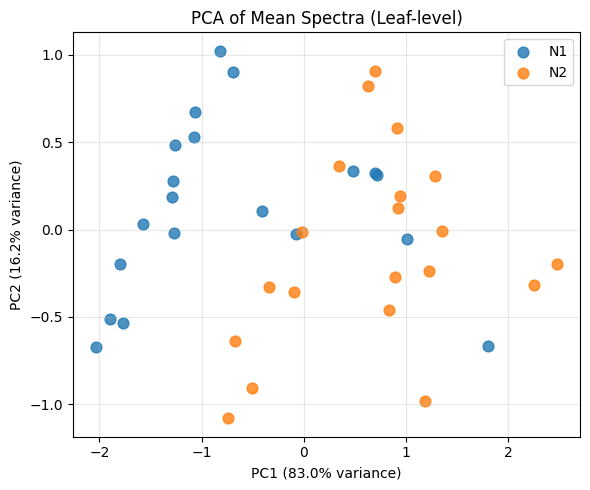

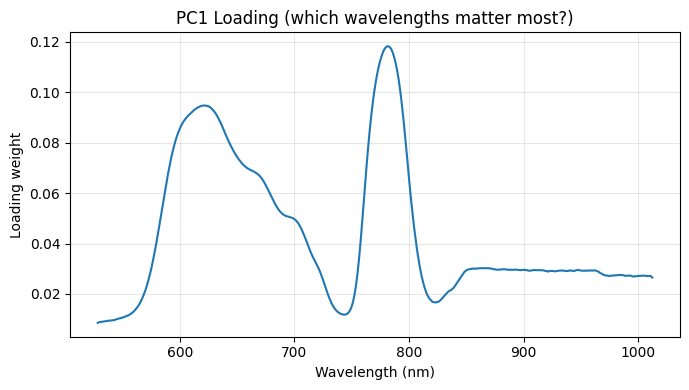

In [8]:
# Step 8: PCA on mean spectra of all leaves

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# ---- Step 8.1: Build matrix of mean spectra for all leaves ----

spectra_list = []
treatments_list = []
filenames_list = []

for idx, row in gt.iterrows():
    file_name = row['file_name']
    treatment = row['treatment']

    raw_path = os.path.join(RAW_DIR, file_name + ".npz")
    seg_path = os.path.join(SEG_DIR, file_name + ".npz")

    if not (os.path.exists(raw_path) and os.path.exists(seg_path)):
        continue

    raw_data = np.load(raw_path)
    seg_data = np.load(seg_path)

    raw_img_i = raw_data[raw_data.files[0]]
    leaf_mask_i = seg_data[seg_data.files[0]]
    leaf_mask_bool_i = leaf_mask_i > 0

    if leaf_mask_bool_i.sum() == 0:
        continue

    # Extract leaf pixels and compute mean spectrum
    leaf_pixels_i = raw_img_i[leaf_mask_bool_i]
    mean_spectrum_i = leaf_pixels_i.mean(axis=0)

    spectra_list.append(mean_spectrum_i)
    treatments_list.append(treatment)
    filenames_list.append(file_name)

spectra_array = np.vstack(spectra_list)
print("Spectra matrix shape:", spectra_array.shape)  # (n_leaves, n_bands)

# ---- Step 8.2: PCA ----

pca = PCA(n_components=3)
pca_scores = pca.fit_transform(spectra_array)     # shape: (n_leaves, 3)
explained = pca.explained_variance_ratio_ * 100

print("PCA explained variance (%):\nPC1={:.1f}%, PC2={:.1f}%, PC3={:.1f}%".format(
    explained[0], explained[1], explained[2]
))

# ---- Step 8.3: Scatterplot of PC1 vs PC2 ----

plt.figure(figsize=(6,5))

for treatment in ["N1", "N2"]:
    mask = np.array(treatments_list) == treatment
    plt.scatter(pca_scores[mask, 0],
                pca_scores[mask, 1],
                label=treatment,
                s=60,
                alpha=0.8)

plt.xlabel(f"PC1 ({explained[0]:.1f}% variance)")
plt.ylabel(f"PC2 ({explained[1]:.1f}% variance)")
plt.title("PCA of Mean Spectra (Leaf-level)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ---- Step 8.4: Plot PC1 loading vector (optional but useful) ----
plt.figure(figsize=(7,4))
plt.plot(wavelengths_global, pca.components_[0], label="PC1 loading")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Loading weight")
plt.title("PC1 Loading (which wavelengths matter most?)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Step 9 - Leaf-Level Logistic Regression Classification (N1 vs N2)

## Objective

Train and evaluate a simple logistic regression classifier to distinguish low-nitrogen (N1) from high-nitrogen (N2) leaves using leaf-level spectral features.

## Rationale

After extracting summary features (indices and reflectance values) for each leaf, logistic regression provides a straightforward baseline model to test whether these features carry enough information to separate nitrogen treatments. It is interpretable, fast, and a good reference point before considering more complex models.

## What this cell does

* Selects a set of leaf-level features from `feature_table`, including:

  * mean_ndvi_leaf
  * mean_ocar_leaf
  * refl_550nm
  * refl_680nm
  * refl_800nm
* Removes any rows with missing values for the selected features or labels.
* Encodes nitrogen treatment as a binary label (N1 = 0, N2 = 1).
* Standardizes all feature columns using z-score normalization.
* Splits the dataset into training and test sets with stratification by label.
* Trains a logistic regression model on the training set.
* Evaluates performance using test accuracy, confusion matrix, and 5-fold cross-validation accuracy.

## Expected output

* Test set accuracy of the logistic regression classifier.
* A confusion matrix showing correct vs incorrect classifications for N1 and N2.
* Mean and standard deviation of 5-fold cross-validation accuracy, summarizing model stability.

In [9]:
# Step 9: Simple classification (Logistic Regression) for N1 vs N2

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt

# ----- Step 9.1: Prepare dataset -----

# Select useful leaf-level features (no base/middle/tip now)
feature_cols = [
    "mean_ndvi_leaf",
    "mean_ocar_leaf",
    "refl_550nm",
    "refl_680nm",
    "refl_800nm"
]

# Drop rows with missing values in features or treatment
df_clf = feature_table.dropna(subset=feature_cols + ["treatment"])

# Encode labels: N1 = 0, N2 = 1
y = (df_clf["treatment"] == "N2").astype(int).values
X = df_clf[feature_cols].values

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ----- Step 9.2: Train-test split -----
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# ----- Step 9.3: Logistic Regression -----
clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)

# Predictions
y_pred = clf.predict(X_test)

# ----- Step 9.4: Accuracy -----
acc = accuracy_score(y_test, y_pred)
print(f"\nTest Accuracy: {acc * 100:.2f}%")

# ----- Step 9.5: Confusion Matrix -----
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# ----- Step 9.6: 5-fold Cross Validation -----
cv_scores = cross_val_score(clf, X_scaled, y, cv=5)
print(
    "\n5-fold CV Accuracy: {:.2f}% (+/- {:.2f})".format(
        cv_scores.mean() * 100, cv_scores.std() * 100
    )
)



Test Accuracy: 90.00%

Confusion Matrix:
[[4 1]
 [0 5]]

5-fold CV Accuracy: 80.00% (+/- 6.12)


## Step 10 - PLS-DA Classification using Leaf-Level Features

## Objective

Use Partial Least Squares Discriminant Analysis (PLS-DA) to classify leaves as low- or high-nitrogen based on leaf-level spectral indices and reflectance features.

## Rationale

PLS-DA is often used in chemometrics and spectral analysis because it can handle multicollinearity and extract latent components that are predictive of class labels. It provides an alternative view to logistic regression and can highlight how many latent spectral components are sufficient to separate N1 and N2 leaves.

## What this cell does

* Selects the same leaf-level features used in logistic regression:

  * mean_ndvi_leaf
  * mean_ocar_leaf
  * refl_550nm
  * refl_680nm
  * refl_800nm
* Drops rows with missing values.
* Encodes treatment as a binary label (N1 = 0, N2 = 1).
* Standardizes all features.
* Splits the dataset into train and test sets with stratified sampling.
* Fits a PLS regression model with a chosen number of components and interprets it as a discriminant model (PLS-DA).
* Converts continuous PLS output scores into class labels using a 0.5 threshold.
* Reports test accuracy and 5-fold cross-validation accuracy.
* Plots the predicted PLS scores versus true class labels, with a horizontal line at 0.5 showing the decision threshold.

## Expected output

* PLS-DA accuracy for the chosen number of components.
* Cross-validation mean accuracy and variability.
* A scatter plot of true labels (0 or 1) versus predicted continuous scores, showing how well N1 and N2 are separated in score space.


PLS-DA Accuracy (3 components): 70.00%
5-fold CV accuracy: 80.00% (+/- 6.12)


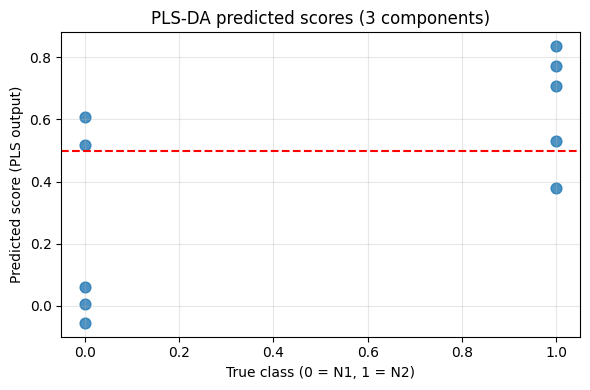

In [10]:
# Step 10: PLS-DA classification (PLS Regression used for discriminant analysis)

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# ---- Step 10.1: Prepare data ----

feature_cols = [
    "mean_ndvi_leaf",
    "mean_ocar_leaf",
    "refl_550nm",
    "refl_680nm",
    "refl_800nm"
]

df_pls = feature_table.dropna(subset=feature_cols + ["treatment"])

X = df_pls[feature_cols].values
y = (df_pls["treatment"] == "N2").astype(int).values  # N2 = 1, N1 = 0

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ---- Step 10.2: Train-test split ----
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.25, random_state=42, stratify=y
)

# ---- Step 10.3: Fit PLS model ----
n_components = 3   # can be tuned

pls = PLSRegression(n_components=n_components)
pls.fit(X_train, y_train)

# Predict continuous scores
y_pred_cont = pls.predict(X_test).ravel()

# Convert to class labels using 0.5 threshold
y_pred = (y_pred_cont >= 0.5).astype(int)

# Accuracy on test set
acc = accuracy_score(y_test, y_pred)
print(f"\nPLS-DA Accuracy ({n_components} components): {acc * 100:.2f}%")

# ---- Step 10.4: 5-fold cross-validation ----
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_acc = []

for train_idx, test_idx in kf.split(X_scaled):
    X_tr, X_te = X_scaled[train_idx], X_scaled[test_idx]
    y_tr, y_te = y[train_idx], y[test_idx]

    pls_cv = PLSRegression(n_components=n_components)
    pls_cv.fit(X_tr, y_tr)

    y_pred_cv_cont = pls_cv.predict(X_te).ravel()
    y_pred_cv = (y_pred_cv_cont >= 0.5).astype(int)
    cv_acc.append(accuracy_score(y_te, y_pred_cv))

print(
    "5-fold CV accuracy: {:.2f}% (+/- {:.2f})".format(
        np.mean(cv_acc) * 100, np.std(cv_acc) * 100
    )
)

# ---- Step 10.5: Plot predicted vs true ----
plt.figure(figsize=(6, 4))
plt.scatter(y_test, y_pred_cont, s=60, alpha=0.8)
plt.axhline(0.5, color="red", linestyle="--")
plt.xlabel("True class (0 = N1, 1 = N2)")
plt.ylabel("Predicted score (PLS output)")
plt.title(f"PLS-DA predicted scores ({n_components} components)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Step 11 - Pixel-Level PCA on Sampled Spectra from All Leaves

## Objective

Explore how individual pixel spectra from all leaves are distributed in a low-dimensional space and assess whether nitrogen treatments (N1 vs N2) show separation at the pixel level.

## Rationale

Leaf-level averages can hide local variability within the leaf. By sampling pixel spectra across all leaves and running PCA, we can see whether nitrogen stress creates distinct spectral clusters at the pixel scale. This helps to understand spatial heterogeneity and motivates pixel-level classification.

## What this cell does

Iterates over all leaves listed in the metadata table.
Loads the hyperspectral cube and the corresponding leaf mask.
Extracts all leaf pixels for each leaf and randomly subsamples a fixed number of pixels per leaf (pixels_per_leaf) to keep the dataset size manageable.
Stacks sampled pixel spectra from all leaves into a single matrix.
Builds a label vector that records the nitrogen treatment (N1 or N2) for each sampled pixel.
Performs PCA with three components on the pixel spectra matrix.
Prints the percentage of variance explained by PC1, PC2, and PC3.
Plots PC1 versus PC2 for all sampled pixels, coloring or separating points by treatment label.

## Expected output

A printed shape of the pixel spectra array, confirming how many pixels and bands are used.
Explained variance percentages for the first three principal components.
A scatter plot of PC1 vs PC2 where each point represents a pixel, showing whether N1 and N2 pixels tend to occupy different regions in the PCA space.

Collected pixel spectra shape: (24000, 364)
PC1=89.6%, PC2=8.1%, PC3=1.1% variance explained


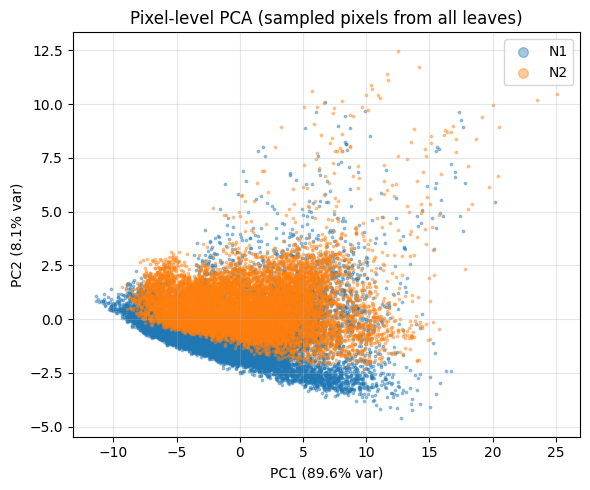

In [11]:
# Step 11: PCA on pixel-level spectral data from all leaves (sampled)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import random

pixel_spectra = []
pixel_labels = []   # N1 or N2
pixel_leaf_id = []  # optional tracking
pixels_per_leaf = 600   # adjustable

print("Collecting pixel spectra...")

for idx, row in gt.iterrows():
    file_name = row['file_name']
    treatment = row['treatment']

    raw_path = os.path.join(RAW_DIR, file_name + ".npz")
    seg_path = os.path.join(SEG_DIR, file_name + ".npz")

    if not (os.path.exists(raw_path) and os.path.exists(seg_path)):
        continue

    raw_data = np.load(raw_path)
    seg_data = np.load(seg_path)

    raw_img_i = raw_data[raw_data.files[0]]
    mask_i = seg_data[seg_data.files[0]] > 0

    # Extract pixel spectra
    leaf_pixels = raw_img_i[mask_i]   # (N_pixels, N_bands)

    # If too many pixels → random sample
    if leaf_pixels.shape[0] > pixels_per_leaf:
        idxs = np.random.choice(leaf_pixels.shape[0], pixels_per_leaf, replace=False)
        leaf_pixels = leaf_pixels[idxs]

    pixel_spectra.append(leaf_pixels)
    pixel_labels += [treatment] * leaf_pixels.shape[0]
    pixel_leaf_id += [file_name] * leaf_pixels.shape[0]

pixel_spectra = np.vstack(pixel_spectra)
pixel_labels = np.array(pixel_labels)

print("Collected pixel spectra shape:", pixel_spectra.shape)

# ---- PCA (3 components) ----
pca = PCA(n_components=3)
scores = pca.fit_transform(pixel_spectra)
expl = pca.explained_variance_ratio_ * 100

print(f"PC1={expl[0]:.1f}%, PC2={expl[1]:.1f}%, PC3={expl[2]:.1f}% variance explained")

# ---- Plot PC1 vs PC2 ----
plt.figure(figsize=(6, 5))

for treatment in ["N1", "N2"]:
    mask = (pixel_labels == treatment)
    plt.scatter(scores[mask, 0], scores[mask, 1], s=3, alpha=0.4, label=treatment)

plt.xlabel(f"PC1 ({expl[0]:.1f}% var)")
plt.ylabel(f"PC2 ({expl[1]:.1f}% var)")
plt.title("Pixel-level PCA (sampled pixels from all leaves)")
plt.legend(markerscale=4)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Step 12 - Model Comparison: Logistic Regression, SVM (RBF), and Random Forest

## Objective

Compare the performance of three different classifiers (Logistic Regression, SVM with RBF kernel, and Random Forest) for distinguishing N1 vs N2 leaves using the leaf-level feature set.

## Rationale

Different models can capture patterns in different ways. Logistic Regression is linear and interpretable, SVM with RBF can model nonlinear boundaries, and Random Forest can capture complex interactions and provide feature importance. A cross-validated comparison helps decide whether simple models are sufficient or if more flexible models provide gains.

## What this cell does

* Selects leaf-level features from `feature_table` (same set as in previous ML cells):

  * mean_ndvi_leaf
  * mean_ocar_leaf
  * refl_550nm
  * refl_680nm
  * refl_800nm
* Drops rows with missing values for these features or treatment.
* Encodes treatment into a binary label (N1 = 0, N2 = 1).
* Standardizes features for models that are sensitive to scale (Logistic Regression and SVM).
* Defines three models:

  * Logistic Regression
  * SVM with RBF kernel
  * Random Forest classifier
* Runs 5-fold stratified cross-validation for each model.
* Reports the mean and standard deviation of cross-validation accuracy for all models in a small summary table.

## Expected output

* Printed dataset shape and class counts for N1 and N2.
* Console lines showing cross-validated accuracy for each model.
* A small DataFrame showing model names, mean CV accuracy, and standard deviation, which can be used directly in the Results section of your report.

In [12]:
# Step 12: Compare Logistic Regression, SVM (RBF), and Random Forest

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# ----- 1. Prepare data from feature_table -----

feature_cols = [
    "mean_ndvi_leaf",
    "mean_ocar_leaf",
    "refl_550nm",
    "refl_680nm",
    "refl_800nm"
]

# Drop rows with missing values in features or treatment
df_ml = feature_table.dropna(subset=feature_cols + ["treatment"]).copy()

# Encode treatment: N1 = 0, N2 = 1
df_ml["label"] = (df_ml["treatment"] == "N2").astype(int)

X = df_ml[feature_cols].values
y = df_ml["label"].values

print("Data shape:", X.shape)
print("Class counts:", np.bincount(y), "(N1=0, N2=1)")

# Standardize features for models that need it
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ----- 2. Define models -----

models = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "SVM_RBF": SVC(kernel="rbf", probability=True),
    "RandomForest": RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        random_state=42
    )
}

# ----- 3. 5-fold cross-validation comparison -----

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

for name, model in models.items():
    # Use scaled features for linear/SVM, raw for tree-based
    if name in ["LogisticRegression", "SVM_RBF"]:
        X_input = X_scaled
    else:
        X_input = X

    scores = cross_val_score(model, X_input, y, cv=cv)
    results.append({
        "Model": name,
        "Mean CV Accuracy": scores.mean(),
        "Std CV Accuracy": scores.std()
    })
    print(f"{name}: CV Accuracy = {scores.mean():.3f} ± {scores.std():.3f}")

# Put results in a DataFrame for a clean view
results_df = pd.DataFrame(results)
print("\n=== Model Comparison (5-fold CV) ===")
display(results_df)


Data shape: (40, 5)
Class counts: [20 20] (N1=0, N2=1)
LogisticRegression: CV Accuracy = 0.800 ± 0.061
SVM_RBF: CV Accuracy = 0.850 ± 0.094
RandomForest: CV Accuracy = 0.800 ± 0.127

=== Model Comparison (5-fold CV) ===


,Model,Mean CV Accuracy,Std CV Accuracy
0,LogisticRegression,0.80,0.061237
1,SVM_RBF,0.85,0.093541
2,RandomForest,0.80,0.127475


## Step 13 - Random Forest Feature Importance on Leaf-Level Features

## Objective

Identify which leaf-level spectral indices and reflectance features contribute most to distinguishing N1 from N2 in a Random Forest classifier.

## Rationale

Even if multiple models achieve good accuracy, it is important to know which features drive the separation between nitrogen treatments. Random Forests provide a natural measure of feature importance that highlights which indices or wavelengths are most informative.

## What this cell does

Selects the leaf-level features from the feature table:
mean_ndvi_leaf
mean_ocar_leaf
refl_550nm
refl_680nm
refl_800nm

Drops rows with missing values and encodes treatment as a binary label (N1 = 0, N2 = 1).
Trains a Random Forest classifier on all available data using these features.
Extracts feature importance scores from the trained Random Forest.
Builds a table ranking features by importance.
Plots a horizontal bar chart showing the relative importance of each feature.

## Expected output

A DataFrame listing each feature and its importance, sorted from most to least important.
A bar plot that visually highlights which indices and reflectance bands are most influential for nitrogen classification.


Random Forest Feature Importances


,Feature,Importance
1,mean_ocar_leaf,0.354301
0,mean_ndvi_leaf,0.238804
3,refl_680nm,0.212012
4,refl_800nm,0.129302
2,refl_550nm,0.065580


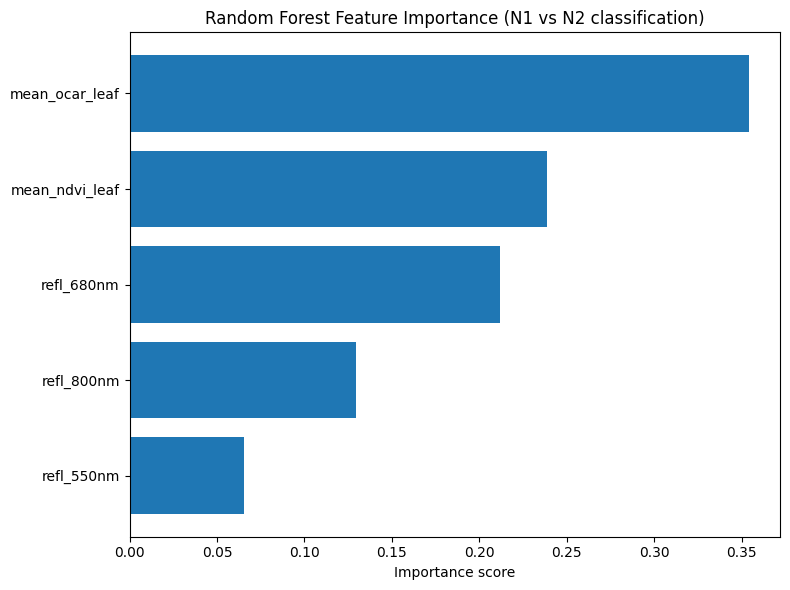

In [13]:
# Step 13: Feature importance from Random Forest on leaf-level features

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

# ---- 1. Prepare data ----

feature_cols = [
    "mean_ndvi_leaf",
    "mean_ocar_leaf",
    "refl_550nm",
    "refl_680nm",
    "refl_800nm"
]

df_fi = feature_table.dropna(subset=feature_cols + ["treatment"]).copy()
df_fi["label"] = (df_fi["treatment"] == "N2").astype(int)

X = df_fi[feature_cols].values
y = df_fi["label"].values

# ---- 2. Train Random Forest ----
rf = RandomForestClassifier(
    n_estimators=400,
    random_state=42,
    max_depth=None
)
rf.fit(X, y)

# ---- 3. Extract feature importances ----
importances = rf.feature_importances_

# Put into a DataFrame for clarity
fi_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

print("\nRandom Forest Feature Importances")
display(fi_df)

# ---- 4. Plot feature importance ----
plt.figure(figsize=(8, 6))
plt.barh(fi_df["Feature"], fi_df["Importance"])
plt.gca().invert_yaxis()
plt.xlabel("Importance score")
plt.title("Random Forest Feature Importance (N1 vs N2 classification)")
plt.tight_layout()
plt.show()


## Step 14 - ROC Curves and AUC for Logistic Regression, SVM, and PLS-DA

## Objective

Evaluate and compare the discrimination ability of three models (Logistic Regression, SVM with RBF kernel, and PLS-DA) for N1 vs N2 classification by plotting ROC curves and computing the Area Under the Curve (AUC).

## Rationale

Accuracy alone does not fully describe classifier performance, especially with potential class imbalance or different decision thresholds. ROC curves and AUC provide a threshold-independent evaluation, showing how well each model separates the two nitrogen classes across all possible decision thresholds.

## What this cell does

* Uses the same leaf-level feature set as earlier classification cells:

  * mean_ndvi_leaf
  * mean_ocar_leaf
  * refl_550nm
  * refl_680nm
  * refl_800nm
* Drops rows with missing values and encodes treatment as a binary label (N1 = 0, N2 = 1).
* Scales the features and creates a single train–test split that is reused for all three models.
* Trains:

  * Logistic Regression
  * SVM with RBF kernel (with probability outputs enabled)
  * PLS-DA using PLSRegression with a fixed number of components
* Obtains predicted probabilities or scores for the test set from each model.
* Computes ROC curves and AUC for each model.
* Plots all ROC curves on the same figure along with a random-chance diagonal line.

## Expected output

* Printed AUC values for Logistic Regression, SVM, and PLS-DA.
* A ROC plot where each model has its own curve and labeled AUC, allowing direct visual comparison.

AUC (LogReg): 0.960
AUC (SVM):    0.720
AUC (PLS-DA): 0.880


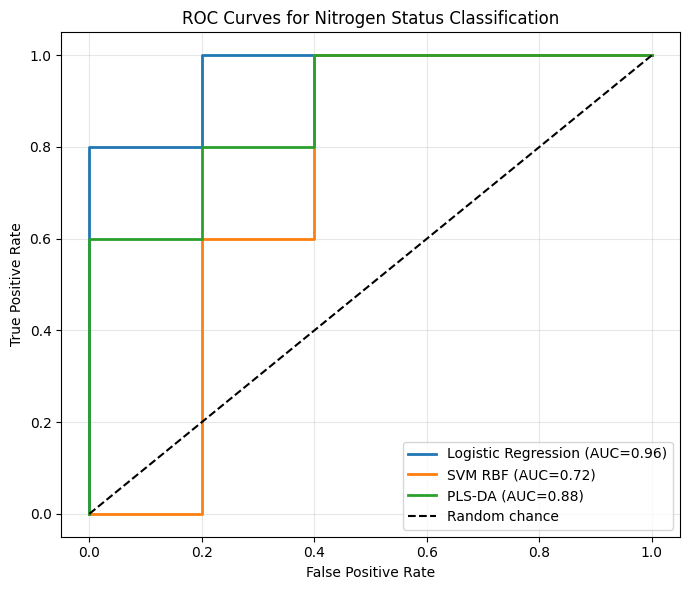

In [14]:
# Step 14: ROC Curves + AUC for Logistic Regression, SVM, and PLS-DA

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.cross_decomposition import PLSRegression

# ----- 1. Prepare data -----

feature_cols = [
    "mean_ndvi_leaf",
    "mean_ocar_leaf",
    "refl_550nm",
    "refl_680nm",
    "refl_800nm"
]

df_roc = feature_table.dropna(subset=feature_cols + ["treatment"]).copy()
df_roc["label"] = (df_roc["treatment"] == "N2").astype(int)

X = df_roc[feature_cols].values
y = df_roc["label"].values

# Standardize features for logistic + SVM + PLS
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-test split (same split for all models)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.25, stratify=y, random_state=42
)

# ----- 2. Train models and get probability outputs -----

# Logistic Regression
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)
probs_log = log_reg.predict_proba(X_test)[:, 1]

# SVM (RBF kernel)
svm = SVC(kernel="rbf", probability=True)
svm.fit(X_train, y_train)
probs_svm = svm.predict_proba(X_test)[:, 1]

# PLS-DA
pls = PLSRegression(n_components=3)
pls.fit(X_train, y_train)
probs_pls = pls.predict(X_test).ravel()

# ----- 3. Compute ROC curves & AUC -----

fpr_log, tpr_log, _ = roc_curve(y_test, probs_log)
fpr_svm, tpr_svm, _ = roc_curve(y_test, probs_svm)
fpr_pls, tpr_pls, _ = roc_curve(y_test, probs_pls)

auc_log = auc(fpr_log, tpr_log)
auc_svm = auc(fpr_svm, tpr_svm)
auc_pls = auc(fpr_pls, tpr_pls)

print(f"AUC (LogReg): {auc_log:.3f}")
print(f"AUC (SVM):    {auc_svm:.3f}")
print(f"AUC (PLS-DA): {auc_pls:.3f}")

# ----- 4. Plot ROC curves -----

plt.figure(figsize=(7, 6))

plt.plot(fpr_log, tpr_log, label=f"Logistic Regression (AUC={auc_log:.2f})", linewidth=2)
plt.plot(fpr_svm, tpr_svm, label=f"SVM RBF (AUC={auc_svm:.2f})", linewidth=2)
plt.plot(fpr_pls, tpr_pls, label=f"PLS-DA (AUC={auc_pls:.2f})", linewidth=2)

plt.plot([0, 1], [0, 1], "k--", label="Random chance")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Nitrogen Status Classification")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Step 15 - Unsupervised K-Means Clustering on Pixel Spectra

## Objective

Group individual leaf pixels into unsupervised spectral clusters and examine how these clusters relate to nitrogen treatment (N1 vs N2).

## Rationale

Clustering at the pixel level helps reveal natural groupings in the spectral data without using treatment labels. If clusters align strongly with N1 or N2, it suggests that nitrogen status produces distinct spectral signatures that an unsupervised method can detect. This supports the idea that nitrogen stress is visible directly in the hyperspectral measurements.

## What this cell does

Collects pixel spectra from each leaf by loading the hyperspectral cube and applying the leaf mask.
Randomly subsamples a fixed number of pixels per leaf (pixels_per_leaf) to control memory and keep the dataset balanced.
Stacks sampled pixel spectra from all leaves into one large matrix and tracks corresponding nitrogen treatment labels.
Standardizes pixel spectra so that all bands contribute equally to distance calculations.
Runs K-Means clustering with K = 2 to find two dominant spectral clusters.
Reduces the standardized spectra to two principal components using PCA for visualization.
Plots pixels in the PC1–PC2 space, colored by their assigned cluster.
Builds a crosstab table comparing cluster assignments vs nitrogen treatment labels to see how well clusters align with N1 and N2.

## Expected output

Printed shape of the pixel spectra matrix and K-Means cluster sizes.
A scatter plot showing cluster structure in PCA space.
A contingency table (cluster vs treatment) that indicates whether clusters are enriched for N1 or N2 pixels.

Pixel spectra shape: (24000, 364)

K-Means cluster sizes: [14618  9382]


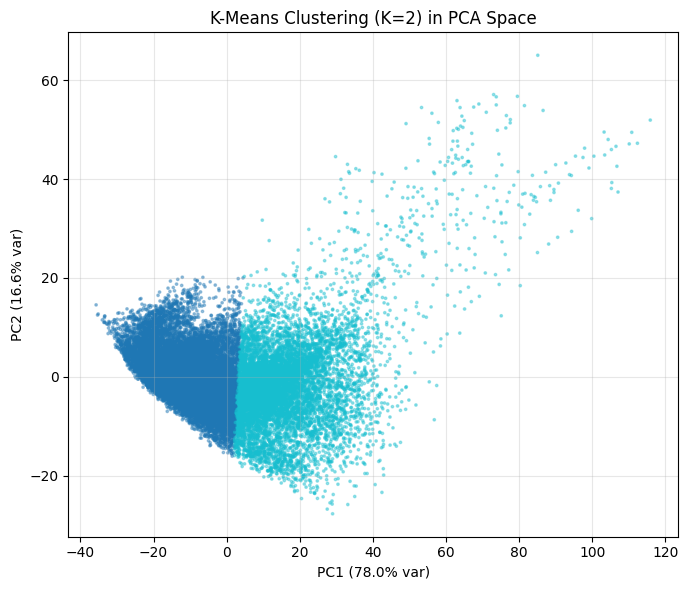


=== Cluster Composition ===


treatment,N1,N2
cluster,,
0,8052,6566
1,3948,5434


In [15]:
# Step 15: Unsupervised K-Means clustering on pixel spectra

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# ---- Step 4.1: Re-sample pixel spectra (if needed) ----
# We will re-sample to avoid memory issues and ensure consistency.

pixel_spectra = []
pixel_labels = []   # N1 / N2 corresponding to each pixel
pixel_leaf_id = []

pixels_per_leaf = 600   # adjust if needed

print("Collecting pixel spectra for K-Means...")

for idx, row in gt.iterrows():
    file_name = row["file_name"]
    treatment = row["treatment"]

    raw_path = os.path.join(RAW_DIR, file_name + ".npz")
    seg_path = os.path.join(SEG_DIR, file_name + ".npz")

    if not (os.path.exists(raw_path) and os.path.exists(seg_path)):
        continue

    raw_data = np.load(raw_path)
    seg_data = np.load(seg_path)

    raw_img_i = raw_data[raw_data.files[0]]
    mask_i = seg_data[seg_data.files[0]] > 0

    leaf_pixels = raw_img_i[mask_i]

    # downsample
    if leaf_pixels.shape[0] > pixels_per_leaf:
        idxs = np.random.choice(leaf_pixels.shape[0], pixels_per_leaf, replace=False)
        leaf_pixels = leaf_pixels[idxs]

    pixel_spectra.append(leaf_pixels)
    pixel_labels += [treatment] * leaf_pixels.shape[0]
    pixel_leaf_id += [file_name] * leaf_pixels.shape[0]

pixel_spectra = np.vstack(pixel_spectra)
pixel_labels = np.array(pixel_labels)

print("Pixel spectra shape:", pixel_spectra.shape)

# ---- Step 4.2: Normalize spectra ----
scaler = StandardScaler()
pixel_spectra_scaled = scaler.fit_transform(pixel_spectra)

# ---- Step 4.3: Run K-Means ----
K = 2   # we expect 2 treatments (N1/N2)
kmeans = KMeans(n_clusters=K, random_state=42)
cluster_ids = kmeans.fit_predict(pixel_spectra_scaled)

print("\nK-Means cluster sizes:", np.bincount(cluster_ids))

# ---- Step 4.4: PCA for visualization ----
pca = PCA(n_components=2)
pixel_scores_2d = pca.fit_transform(pixel_spectra_scaled)

expl1, expl2 = pca.explained_variance_ratio_[:2] * 100

plt.figure(figsize=(7,6))
plt.scatter(pixel_scores_2d[:,0], pixel_scores_2d[:,1],
            c=cluster_ids, cmap="tab10", s=3, alpha=0.4)
plt.xlabel(f"PC1 ({expl1:.1f}% var)")
plt.ylabel(f"PC2 ({expl2:.1f}% var)")
plt.title("K-Means Clustering (K=2) in PCA Space")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---- Step 4.5: Compare clusters vs treatment ----

df_clusters = pd.DataFrame({
    "cluster": cluster_ids,
    "treatment": pixel_labels
})

cluster_summary = pd.crosstab(df_clusters["cluster"], df_clusters["treatment"])

print("\n=== Cluster Composition ===")
display(cluster_summary)


## Step 16 - Pixel-Level Classifier using PCA + Logistic Regression

## Objective

Train a pixel-level classifier that predicts nitrogen status (N1 vs N2) for individual pixels using reduced hyperspectral features (principal components), while ensuring that train and test sets are separated by leaf.

## Rationale

Leaf-level models treat each leaf as a single sample and ignore within-leaf spatial variability. A pixel-level model uses local spectral information and can generate probability heatmaps showing where on the leaf nitrogen stress is most evident. Splitting train/test by leaf prevents information leakage from pixels of the same leaf appearing in both sets.

## What this cell does

Collects pixel spectra for each leaf by loading the hyperspectral cube and applying the leaf mask.
Randomly subsamples a fixed number of pixels per leaf (pixels_per_leaf) to control memory usage while keeping a balanced representation.
Builds arrays for:

* pixel_spectra_all — all sampled pixel spectra
* pixel_labels_all — treatment label (N1 or N2) for each pixel
* pixel_leaf_id_all — leaf ID to which each pixel belongs
  Encodes pixel labels as binary (N1 = 0, N2 = 1).
  Performs a train–test split at the leaf level: some leaves are used for training, the remaining leaves for testing.
  Standardizes pixel spectra and reduces dimensionality from all bands to 10 principal components using PCA.
  Trains a pixel-level Logistic Regression classifier on the PCA scores (option to switch to SVM).
  Evaluates the classifier on the held-out leaf pixels, printing accuracy and confusion matrix.
  Stores the trained scaler, PCA model, and classifier (scaler_model, pca_model, pixel_classifier) for later use in nitrogen probability heatmap visualization.

## Expected output

Printed shapes for collected pixel spectra, train/test pixel counts, and PCA-transformed feature dimensions.
Pixel-level test accuracy and a confusion matrix summarizing correct and incorrect N1/N2 predictions at the pixel scale.
A confirmation message indicating that the PCA model and classifier are ready for generating pixel-wise nitrogen probability maps.

In [16]:
# Step 16: Build a pixel-level classifier using PCA + Logistic Regression / SVM

import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

print("Collecting pixel spectra per leaf (train/test split by leaf)...")

# --------------------------
# Step 6.1 — Collect data leaf-by-leaf
# --------------------------

pixel_spectra_all = []
pixel_labels_all = []
pixel_leaf_id_all = []

pixels_per_leaf = 600  # adjust if needed

for idx, row in gt.iterrows():
    file_name = row["file_name"]
    treatment = row["treatment"]   # label for all pixels in leaf

    raw_path = os.path.join(RAW_DIR, file_name + ".npz")
    seg_path = os.path.join(SEG_DIR, file_name + ".npz")

    if not (os.path.exists(raw_path) and os.path.exists(seg_path)):
        continue

    raw_data = np.load(raw_path)
    seg_data = np.load(seg_path)

    raw_img = raw_data[raw_data.files[0]]        # (H, W, Bands)
    mask = seg_data[seg_data.files[0]] > 0       # (H, W)

    # Extract all leaf pixels (N_pixels × Bands)
    leaf_pixels = raw_img[mask]

    # Downsample for memory efficiency
    if leaf_pixels.shape[0] > pixels_per_leaf:
        idxs = np.random.choice(leaf_pixels.shape[0], pixels_per_leaf, replace=False)
        leaf_pixels = leaf_pixels[idxs]

    pixel_spectra_all.append(leaf_pixels)
    pixel_labels_all += [treatment] * leaf_pixels.shape[0]
    pixel_leaf_id_all += [file_name] * leaf_pixels.shape[0]

pixel_spectra_all = np.vstack(pixel_spectra_all)
pixel_labels_all = np.array(pixel_labels_all)
pixel_leaf_id_all = np.array(pixel_leaf_id_all)

print("Collected pixel spectra:", pixel_spectra_all.shape)
print("Pixel labels sample:", pixel_labels_all[:10])

# Encode labels: N1=0, N2=1
pixel_y = (pixel_labels_all == "N2").astype(int)

# --------------------------
# Step 6.2 — Train/test split *by leaf*, not pixels
# --------------------------

unique_leaves = np.unique(pixel_leaf_id_all)
train_leaves, test_leaves = train_test_split(
    unique_leaves, test_size=0.25, random_state=42, stratify=None
)

is_train = np.isin(pixel_leaf_id_all, train_leaves)
is_test  = np.isin(pixel_leaf_id_all, test_leaves)

X_train_raw = pixel_spectra_all[is_train]
X_test_raw  = pixel_spectra_all[is_test]
y_train = pixel_y[is_train]
y_test  = pixel_y[is_test]

print("Train pixels:", X_train_raw.shape, "Test pixels:", X_test_raw.shape)

# --------------------------
# Step 6.3 — Standardize & PCA
# --------------------------

scaler_px = StandardScaler()
X_train_scaled = scaler_px.fit_transform(X_train_raw)
X_test_scaled  = scaler_px.transform(X_test_raw)

# PCA reduce 364 bands → 10 PCs
pca_px = PCA(n_components=10)
X_train_pca = pca_px.fit_transform(X_train_scaled)
X_test_pca  = pca_px.transform(X_test_scaled)

print("Train PCA shape:", X_train_pca.shape)

# --------------------------
# Step 6.4 — Train pixel-level classifier
# --------------------------

# Logistic Regression (simple & interpretable)
clf_px = LogisticRegression(max_iter=1000)
clf_px.fit(X_train_pca, y_train)

# SVM alternative (you can switch to this)
# clf_px = SVC(kernel='rbf', probability=True)
# clf_px.fit(X_train_pca, y_train)

# --------------------------
# Step 6.5 — Evaluate model
# --------------------------

from sklearn.metrics import accuracy_score, confusion_matrix

y_pred = clf_px.predict(X_test_pca)
acc = accuracy_score(y_test, y_pred)

print(f"\nPixel-level accuracy (test set): {acc:.3f}")
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

# Save model objects for heatmap:
pca_model = pca_px
scaler_model = scaler_px
pixel_classifier = clf_px

print("\nPixel-level PCA model and classifier are ready for heatmap generation.")


Collected pixel spectra: (24000, 364)
Pixel labels sample: ['N1' 'N1' 'N1' 'N1' 'N1' 'N1' 'N1' 'N1' 'N1' 'N1']
Train pixels: (18000, 364) Test pixels: (6000, 364)
Train PCA shape: (18000, 10)

Pixel-level accuracy (test set): 0.663
Confusion matrix:
[[1464  936]
 [1083 2517]]

Pixel-level PCA model and classifier are ready for heatmap generation.


## Step 17 - Pixel-Level Nitrogen Probability Heatmap

## Objective

Visualize the spatial distribution of predicted nitrogen status within a single leaf by converting pixel-level classifier outputs into a probability heatmap.

## Rationale

Leaf-level and pixel-level models quantify nitrogen effects numerically, but a 2D probability map shows where on the leaf those effects are strongest (for example, tip, edges, or veins). This is very intuitive for presentation and helps connect spectral classification to plant physiology.

## What this cell does

Selects one leaf from the metadata table for visualization.
Loads the corresponding hyperspectral cube and leaf mask.
Extracts all leaf pixel spectra for that leaf using the mask.
Applies the previously trained pixel-level preprocessing steps:
standardization with scaler_model
dimensionality reduction with pca_model
Uses the trained pixel-level classifier (pixel_classifier) to compute, for each pixel, the probability that it belongs to the N2 (high nitrogen) class.
Fills a 2D array with these probabilities at leaf pixel locations and sets background pixels to NaN.
Plots three panels side by side:
an example spectral band image of the leaf
the leaf mask
the nitrogen probability heatmap with a colorbar from 0 to 1

## Expected output

Console print showing which leaf is visualized and the hyperspectral cube dimensions.
A figure with three subplots:
grayscale mid-band image of the leaf
binary mask of the leaf
colored heatmap showing pixel-wise N2 probability, where warmer colors indicate more N2-like spectra

Using example leaf: 22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-46_11-25-2021_14-53-36
Image shape: (224, 1111, 364)


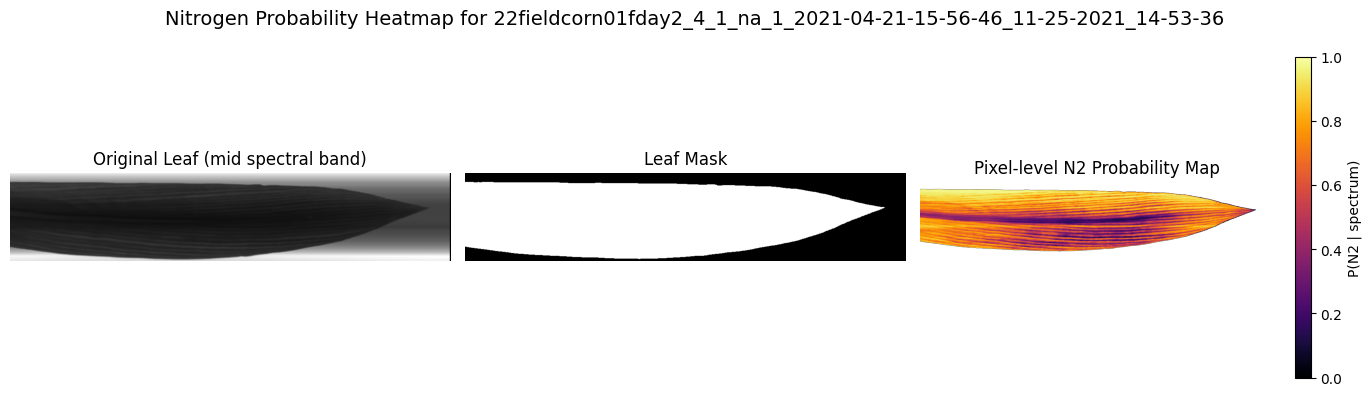

In [17]:
# Step 17: Pixel-level nitrogen probability heatmap using PCA + pixel classifier

import numpy as np
import matplotlib.pyplot as plt

# ------------------------
# Choose a leaf to visualize
# ------------------------
# You can change the index here to visualize another leaf
example_leaf = gt['file_name'].iloc[0]
print("Using example leaf:", example_leaf)

raw_path = os.path.join(RAW_DIR, example_leaf + ".npz")
seg_path = os.path.join(SEG_DIR, example_leaf + ".npz")

raw_data_ex = np.load(raw_path)
seg_data_ex = np.load(seg_path)

raw_img_ex = raw_data_ex[raw_data_ex.files[0]]   # (H, W, Bands)
mask_ex = seg_data_ex[seg_data_ex.files[0]] > 0  # (H, W)

H, W, B = raw_img_ex.shape
print("Image shape:", raw_img_ex.shape)

# ------------------------
# Extract pixel spectra for this leaf
# ------------------------
leaf_pixels = raw_img_ex[mask_ex]   # (N_pixels, B)

# Standardize & PCA-transform using the *pixel-level* models
leaf_pixels_scaled = scaler_model.transform(leaf_pixels)
leaf_pixels_pca = pca_model.transform(leaf_pixels_scaled)

# Predict probability of N2 for each pixel
pixel_probs = pixel_classifier.predict_proba(leaf_pixels_pca)[:, 1]

# Put probabilities back into 2D image
prob_map = np.zeros((H, W), dtype=float)
prob_map[:] = np.nan   # background as NaN
prob_map[mask_ex] = pixel_probs

# ------------------------
# Plot the results
# ------------------------
plt.figure(figsize=(14,4))

# 1) Original leaf (one spectral band)
mid_band = B // 2
plt.subplot(1,3,1)
plt.imshow(raw_img_ex[:, :, mid_band], cmap='gray')
plt.title("Original Leaf (mid spectral band)")
plt.axis('off')

# 2) Leaf mask
plt.subplot(1,3,2)
plt.imshow(mask_ex, cmap='gray')
plt.title("Leaf Mask")
plt.axis('off')

# 3) Nitrogen probability map
plt.subplot(1,3,3)
im = plt.imshow(prob_map, cmap='inferno', vmin=0, vmax=1)
plt.title("Pixel-level N2 Probability Map")
plt.axis('off')
cbar = plt.colorbar(im)
cbar.set_label("P(N2 | spectrum)")

plt.suptitle(f"Nitrogen Probability Heatmap for {example_leaf}", fontsize=14)
plt.tight_layout()
plt.show()


## Step 18 - Anatomical Region Nitrogen Probability Analysis

## Objective

Compare the predicted nitrogen probability scores across anatomically defined leaf regions using segmentation masks.

## Rationale

Nitrogen stress alters chlorophyll absorption and red-edge reflectance differently in different plant tissues. Using anatomical masks enables region-specific inspection of how nitrogen-like each tissue zone appears based on the pixel classifier.

## Key Operations

* Select one leaf from metadata
* Load hyperspectral cube and segmentation masks
* Recompute pixel-level nitrogen probability map using trained models
* Apply anatomical region masks:

  * Leaf (full tissue area)
  * Veins
  * Midrib
  * Mesophyll
  * Leaf Edge
  * Leaf Tip
* Extract pixel classifier probability values for each mask
* Compute the mean nitrogen probability score per region
* Plot a bar chart comparing nitrogen probability means for all anatomical regions

## Expected Outcome

* Printed mean nitrogen probability per anatomical region
* A bar plot showing tissue-wise nitrogen sensitivity

Using leaf: 22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-46_11-25-2021_14-53-36

Mean N2-like probability per anatomical region:
Leaf: 0.644
CleanLeaf: 0.644
Veins: 0.548
Midrib: 0.318
Mesophyll: 0.674
LeafEdge: 0.756
LeafTip: 0.662


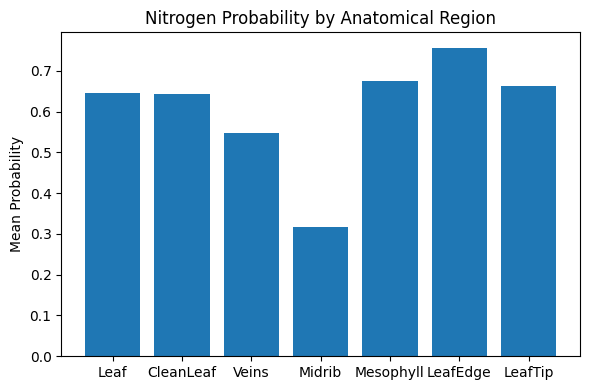

In [18]:
# Step 18: Compare nitrogen probability across anatomical regions

import numpy as np
import matplotlib.pyplot as plt
import os

# Use the first leaf or change index if needed
leaf_name = gt["file_name"].iloc[0]
print("Using leaf:", leaf_name)

# Load hyperspectral cube + segmentation masks
raw_ex = np.load(os.path.join(RAW_DIR, leaf_name + ".npz"))
seg_ex = np.load(os.path.join(SEG_DIR, leaf_name + ".npz"))

cube = raw_ex[raw_ex.files[0]]  # (H, W, Bands)
mask_leaf = seg_ex["leaf_mask"] > 0

H, W, B = cube.shape

# Recompute probability map using pixel classifier
pixels = cube[mask_leaf]
px_scaled = scaler_model.transform(pixels)
px_pca = pca_model.transform(px_scaled)
probs = pixel_classifier.predict_proba(px_pca)[:, 1]

prob_img = np.full((H, W), np.nan)
prob_img[mask_leaf] = probs

# Define anatomical masks
anat_masks = {
    "Leaf":        seg_ex["leaf_mask"]      > 0,
    "CleanLeaf":   seg_ex["cln_leaf_mask"]  > 0,
    "Veins":       seg_ex["vein_mask"]      > 0,
    "Midrib":      seg_ex["mrib_mask"]      > 0,
    "Mesophyll":   seg_ex["meso_mask"]      > 0,
    "LeafEdge":    seg_ex["leaf_edge_mask"] > 0,
    "LeafTip":     seg_ex["leaf_tip_mask"]  > 0,
}

means = {}
print("\nMean N2-like probability per anatomical region:")

for name, m in anat_masks.items():
    vals = prob_img[m]
    means[name] = np.nanmean(vals)
    print(f"{name}: {means[name]:.3f}")

# Plot bar chart
plt.figure(figsize=(6,4))
plt.bar(means.keys(), means.values())
plt.title("Nitrogen Probability by Anatomical Region")
plt.ylabel("Mean Probability")
plt.tight_layout()
plt.show()


## Step 19 - Nitrogen Difference Map: P(N2) − NDVI

## Objective

Compare a traditional vegetation index (NDVI) with the pixel-level nitrogen probability from the ML classifier and visualize where they agree or disagree on the leaf surface.

## Rationale

NDVI is a simple, widely used proxy for chlorophyll and nitrogen status, while the ML model uses many spectral bands (via PCA) to estimate nitrogen probability. A difference map (P(N2) − NDVI) highlights regions where the model detects stronger or weaker nitrogen signals than NDVI alone, which is useful for interpretation and discussion.

## What this cell does

* Selects one example leaf and loads its hyperspectral cube and mask.
* Computes an NDVI map using the red (~680 nm) and NIR (~800 nm) bands.
* Masks NDVI so only leaf pixels are retained.
* Recomputes the pixel-wise N2 probability map using the trained scaler, PCA model, and pixel classifier.
* Constructs a difference map as:
  P(N2) − NDVI
  where positive values indicate pixels where the model predicts more N2-like behavior than NDVI suggests, and negative values indicate the opposite.
* Plots three side-by-side panels:

  * NDVI map
  * P(N2) map
  * Difference map with a diverging color scale

## Expected output

* NDVI map showing spatial variation in index values across the leaf.
* P(N2) heatmap from the ML classifier.
* Difference map where warm colors (positive) highlight pixels where the classifier “sees” more nitrogen than NDVI, and cool colors (negative) where NDVI is stronger than the ML probability.

Using example leaf: 22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-46_11-25-2021_14-53-36


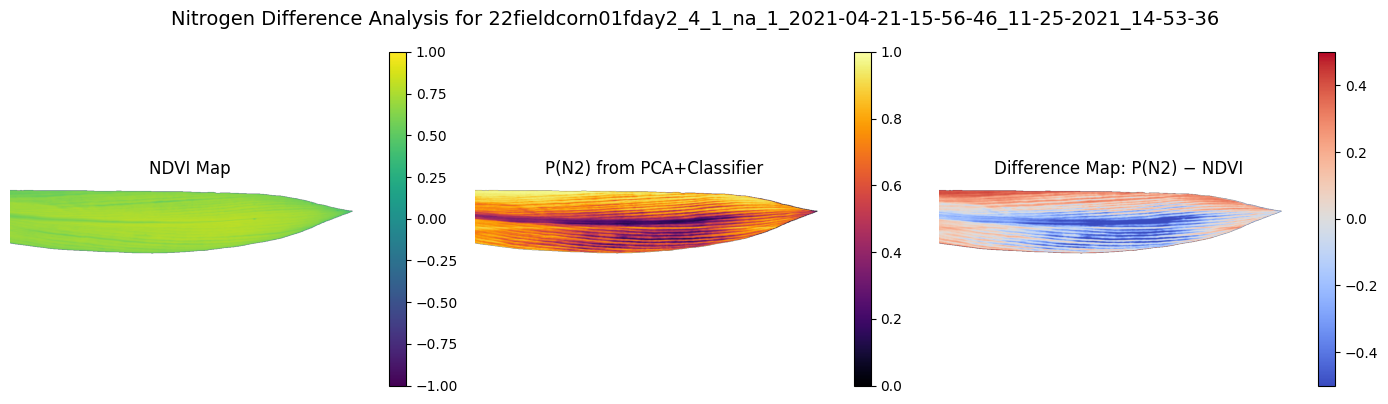

In [19]:
# Step 19: Nitrogen Difference Map (P(N2) − NDVI)

import numpy as np
import matplotlib.pyplot as plt

# -------------------------------
# Use same leaf as before
# -------------------------------
example_leaf = gt['file_name'].iloc[0]
print("Using example leaf:", example_leaf)

raw_path = os.path.join(RAW_DIR, example_leaf + ".npz")
seg_path = os.path.join(SEG_DIR, example_leaf + ".npz")

raw_data_ex = np.load(raw_path)
seg_data_ex = np.load(seg_path)

raw_img_ex = raw_data_ex[raw_data_ex.files[0]]   # (H, W, Bands)
mask_ex = seg_data_ex[seg_data_ex.files[0]] > 0  # True leaf mask

H, W, B = raw_img_ex.shape

# -------------------------------------
# STEP 1 — Compute NDVI map for the leaf
# -------------------------------------
# Use the same indices you used earlier
red_idx    = find_band_for_wavelength(680, wavelengths_global)
nir_idx    = find_band_for_wavelength(800, wavelengths_global)

eps = 1e-8
red_img = raw_img_ex[:,:,red_idx].astype(float)
nir_img = raw_img_ex[:,:,nir_idx].astype(float)

ndvi_map = (nir_img - red_img) / (nir_img + red_img + eps)
ndvi_map_masked = np.where(mask_ex, ndvi_map, np.nan)

# -------------------------------------
# STEP 2 — Compute P(N2) map using PCA + pixel classifier
# -------------------------------------
leaf_pixels = raw_img_ex[mask_ex]
leaf_pixels_scaled = scaler_model.transform(leaf_pixels)
leaf_pixels_pca = pca_model.transform(leaf_pixels_scaled)
pixel_probs = pixel_classifier.predict_proba(leaf_pixels_pca)[:, 1]

prob_map = np.full((H, W), np.nan)
prob_map[mask_ex] = pixel_probs

# -------------------------------------
# STEP 3 — Compute Difference Map: ML – NDVI
# -------------------------------------
diff_map = prob_map - ndvi_map_masked  # positive = model says more N2 than NDVI suggests

# -------------------------------------
# STEP 4 — Plot NDVI vs P(N2) vs Difference
# -------------------------------------
plt.figure(figsize=(14,4))

# NDVI
plt.subplot(1,3,1)
im1 = plt.imshow(ndvi_map_masked, cmap='viridis', vmin=-1, vmax=1)
plt.title("NDVI Map")
plt.axis('off')
plt.colorbar(im1, fraction=0.046)

# P(N2)
plt.subplot(1,3,2)
im2 = plt.imshow(prob_map, cmap='inferno', vmin=0, vmax=1)
plt.title("P(N2) from PCA+Classifier")
plt.axis('off')
plt.colorbar(im2, fraction=0.046)

# Difference
plt.subplot(1,3,3)
# diverging colormap for differences
im3 = plt.imshow(diff_map, cmap='coolwarm', vmin=-0.5, vmax=0.5)
plt.title("Difference Map: P(N2) − NDVI")
plt.axis('off')
plt.colorbar(im3, fraction=0.046)

plt.suptitle(f"Nitrogen Difference Analysis for {example_leaf}", fontsize=14)
plt.tight_layout()
plt.show()


## Step 20 - Per-leaf Nitrogen Score from Pixel-Level Classifier

## Objective

Aggregate pixel-level N2 probabilities into a single nitrogen score per leaf and compare these scores between N1 and N2 treatments.

## Rationale

Pixel-level predictions capture local spectral variability, but for treatment comparison and reporting it is useful to condense this into a single scalar per leaf. The mean pixel-level N2 probability provides a model-based “nitrogen score” that can be directly compared to ground-truth treatments (N1 vs N2) and combined with leaf-level spectral features.

## What this cell does

Iterates over all leaves defined in the metadata table.
For each leaf:

* Loads its hyperspectral cube and segmentation mask
* Extracts all leaf pixels using the mask
* Applies the trained pixel-level preprocessing pipeline:

  * standardization using scaler_model
  * PCA projection using pca_model
* Uses the pixel classifier to compute P(N2) for every leaf pixel
* Computes a leaf-level nitrogen score as the mean of pixel P(N2)
  Stores file_name, treatment, and leaf_n_score for each leaf into a DataFrame (leaf_score_df).
  Optionally merges leaf nitrogen scores with the existing feature_table for richer analysis.
  Creates a boxplot comparing leaf_n_score for N1 vs N2 leaves.
  Prints mean leaf_n_score grouped by treatment.

## Expected output

A table of per-leaf nitrogen scores with corresponding treatments.
A merged table (if feature_table exists) containing both spectral features and nitrogen scores.
A boxplot showing how leaf_n_score differs between N1 and N2.
Printed mean nitrogen scores for each treatment group, illustrating separation between low- and high-nitrogen leaves according to the pixel-level model.


Computing per-leaf nitrogen scores...

Per-leaf nitrogen scores (first few rows):


,file_name,treatment,leaf_n_score
0,22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-4...,N1,0.644264
1,22fieldcorn01fday2_4_2_na_1_2021-04-21-15-57-4...,N1,0.059178
2,22fieldcorn01fday2_4_3_na_1_2021-04-21-15-58-4...,N1,0.057471
3,22fieldcorn01fday2_4_1_na_2_2021-04-21-15-53-3...,N1,0.518259
4,22fieldcorn01fday2_4_2_na_2_2021-04-21-15-54-3...,N1,0.068178



Merged leaf features + nitrogen scores (first few rows):


,file_name,treatment,mean_ndvi_leaf,mean_ocar_leaf,refl_550nm,refl_680nm,refl_800nm,leaf_n_score
0,22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-4...,N1,0.691367,0.244532,0.267007,0.269239,1.408893,0.644264
1,22fieldcorn01fday2_4_2_na_1_2021-04-21-15-57-4...,N1,0.783000,0.261719,0.264423,0.160427,1.264816,0.059178
2,22fieldcorn01fday2_4_3_na_1_2021-04-21-15-58-4...,N1,0.783749,0.259463,0.250563,0.156097,1.226135,0.057471
3,22fieldcorn01fday2_4_1_na_2_2021-04-21-15-53-3...,N1,0.716784,0.250067,0.258377,0.232647,1.355301,0.518259
4,22fieldcorn01fday2_4_2_na_2_2021-04-21-15-54-3...,N1,0.776546,0.259444,0.264291,0.170545,1.314709,0.068178


/var/folders/m3/dmdf9gcd7l1bdgq8whr7kbjr0000gn/T/ipykernel_69837/4248058790.py:73: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([group_N1, group_N2],


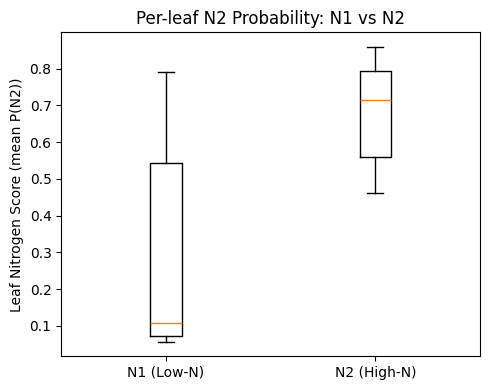


Mean leaf_n_score by treatment:
treatment
N1    0.274583
N2    0.682550
Name: leaf_n_score, dtype: float64


In [20]:
# Step 20: Per-leaf nitrogen score using pixel-level classifier

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

leaf_scores = []

print("Computing per-leaf nitrogen scores...")

for idx, row in gt.iterrows():
    file_name = row["file_name"]
    treatment = row["treatment"]

    raw_path = os.path.join(RAW_DIR, file_name + ".npz")
    seg_path = os.path.join(SEG_DIR, file_name + ".npz")

    if not (os.path.exists(raw_path) and os.path.exists(seg_path)):
        print(f"Skipping {file_name}: missing raw or seg file.")
        continue

    raw_data = np.load(raw_path)
    seg_data = np.load(seg_path)

    raw_img = raw_data[raw_data.files[0]]      # (H, W, Bands)
    mask = seg_data[seg_data.files[0]] > 0     # (H, W)

    if mask.sum() == 0:
        print(f"Skipping {file_name}: no leaf pixels in mask.")
        continue

    H, W, B = raw_img.shape

    # Pixel spectra
    leaf_pixels = raw_img[mask]  # (N_pixels, B)

    # Standardize & PCA-transform using pixel-level models
    leaf_pixels_scaled = scaler_model.transform(leaf_pixels)
    leaf_pixels_pca = pca_model.transform(leaf_pixels_scaled)

    # Pixel-level probability of N2
    pixel_probs = pixel_classifier.predict_proba(leaf_pixels_pca)[:, 1]

    # Leaf-level nitrogen score = mean P(N2)
    mean_prob = float(np.mean(pixel_probs))

    leaf_scores.append({
        "file_name": file_name,
        "treatment": treatment,
        "leaf_n_score": mean_prob
    })

# Build DataFrame
leaf_score_df = pd.DataFrame(leaf_scores)
print("\nPer-leaf nitrogen scores (first few rows):")
display(leaf_score_df.head())

# Merge with feature_table (optional, for richer analysis)
if "feature_table" in globals():
    # use inner join on file_name
    leaf_merged = pd.merge(feature_table, leaf_score_df,
                           on=["file_name", "treatment"], how="inner")
    print("\nMerged leaf features + nitrogen scores (first few rows):")
    display(leaf_merged.head())
else:
    leaf_merged = leaf_score_df

# ---- Boxplot: N1 vs N2 leaf_n_score ----
group_N1 = leaf_merged[leaf_merged["treatment"] == "N1"]["leaf_n_score"]
group_N2 = leaf_merged[leaf_merged["treatment"] == "N2"]["leaf_n_score"]

plt.figure(figsize=(5,4))
plt.boxplot([group_N1, group_N2],
            labels=["N1 (Low-N)", "N2 (High-N)"])
plt.ylabel("Leaf Nitrogen Score (mean P(N2))")
plt.title("Per-leaf N2 Probability: N1 vs N2")
plt.tight_layout()
plt.show()

print("\nMean leaf_n_score by treatment:")
print(leaf_merged.groupby("treatment")["leaf_n_score"].mean())


## Step 21 - Vertical Nitrogen Gradient Profile

## Objective

Analyze nitrogen probability variation along the leaf length by aggregating classifier scores row-wise from the base to tip and plotting a continuous gradient profile.

## Rationale

Nitrogen availability influences chlorophyll concentration and reflectance progressively along the corn leaf. A vertical gradient plot helps inspect whether nitrogen probability increases or decreases smoothly from the leaf base to the tip, making the nitrogen response spatially interpretable.

## Key Operations

Select one corn leaf hyperspectral cube for analysis.
Generate a pixel-wise nitrogen probability map using the trained preprocessing pipeline (scaler → PCA → classifier).
Identify the vertical span of the leaf using the mask.
Compute average nitrogen probability for each valid horizontal row of leaf pixels.
Plot a curve showing nitrogen probability change against normalized leaf height (0 to 1 scale).

## Expected Output

A smooth line plot representing nitrogen probability trend along the leaf axis.
Printed count of vertical positions summarized for the gradient profile.

Using example leaf: 22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-46_11-25-2021_14-53-36


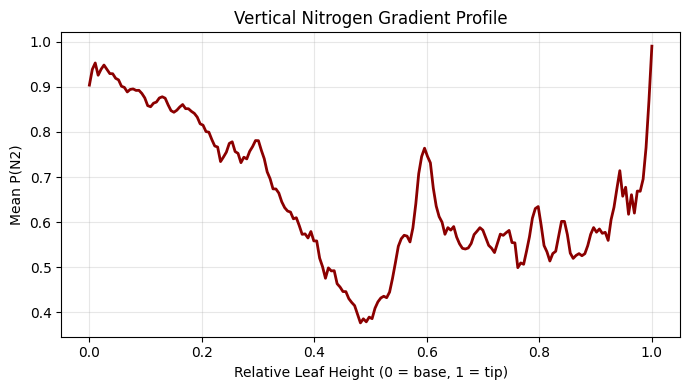

Gradient computed for 194 vertical positions.


In [21]:
# Step 21: Vertical nitrogen gradient profile (base → tip)

import numpy as np
import matplotlib.pyplot as plt

# Choose an example leaf (change index to analyze another)
example_leaf = gt['file_name'].iloc[0]
print("Using example leaf:", example_leaf)

raw_path = os.path.join(RAW_DIR, example_leaf + ".npz")
seg_path = os.path.join(SEG_DIR, example_leaf + ".npz")

raw_data = np.load(raw_path)
seg_data = np.load(seg_path)

raw_img = raw_data[raw_data.files[0]]    # (H, W, bands)
mask = seg_data[seg_data.files[0]] > 0   # leaf mask

H, W, B = raw_img.shape

# -------------------------------------------
# Step 1 — Compute pixel-level nitrogen map
# -------------------------------------------
leaf_pixels = raw_img[mask]
leaf_pixels_scaled = scaler_model.transform(leaf_pixels)
leaf_pixels_pca = pca_model.transform(leaf_pixels_scaled)
pixel_probs = pixel_classifier.predict_proba(leaf_pixels_pca)[:, 1]

prob_map = np.full((H, W), np.nan)
prob_map[mask] = pixel_probs

# -------------------------------------------
# Step 2 — Compute vertical gradient
# -------------------------------------------
rows = np.where(mask.any(axis=1))[0]
row_min, row_max = rows.min(), rows.max()

gradient_vals = []
relative_height = []

for r in range(row_min, row_max + 1):
    row_mask = mask[r, :]
    if row_mask.sum() == 0:
        continue
    row_probs = prob_map[r, row_mask]
    gradient_vals.append(np.nanmean(row_probs))
    relative_height.append((r - row_min) / (row_max - row_min))  # 0 to 1 scale

gradient_vals = np.array(gradient_vals)
relative_height = np.array(relative_height)

# -------------------------------------------
# Step 3 — Plot gradient profile
# -------------------------------------------
plt.figure(figsize=(7,4))
plt.plot(relative_height, gradient_vals, color="darkred", linewidth=2)
plt.xlabel("Relative Leaf Height (0 = base, 1 = tip)")
plt.ylabel("Mean P(N2)")
plt.title("Vertical Nitrogen Gradient Profile")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Gradient computed for", len(gradient_vals), "vertical positions.")


## Step 22- Spectral PCA False-Color Composite (PC1, PC2, PC3 → RGB)

## Objective

Create a false-color image of the leaf by using the first three spectral principal components as red, green, and blue channels.

## Rationale

Hyperspectral data are high dimensional and not directly visible. By applying PCA across spectral bands and mapping PC1, PC2, and PC3 to RGB, we compress spectral information into a three-channel image that visually enhances subtle spectral differences across the leaf. This helps interpret spatial patterns that may relate to nitrogen status or other physiological variations.

## Key Operations

Select one hyperspectral leaf cube and its corresponding leaf mask.
Extract leaf pixels and reshape them into a matrix of size (number of leaf pixels, number of bands).
Standardize each band (subtract mean, divide by standard deviation) so PCA is not dominated by high-magnitude bands.
Apply PCA to the standardized spectra and keep the first three principal components for each pixel.
Project PC1, PC2, and PC3 back to the 2D leaf image grid using the mask.
Normalize each PC map to a 0–1 range for display.
Stack normalized PC1, PC2, and PC3 as red, green, and blue channels to form an RGB false-color image.
Plot:
mid spectral band in grayscale
normalized PC1 image
normalized PC2 image
the RGB false-color composite

## Expected output

Printed explained variance percentages for the three PCs, showing how much spectral variability each captures.
A multi-panel figure displaying:
the original mid-band grayscale image
PC1 and PC2 maps
a colorful PCA-based composite where different tissue zones or stress patterns may appear with distinct colors.

Using example leaf: 22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-46_11-25-2021_14-53-36
Image shape: (224, 1111, 364)
Explained variance (%): [85.01865384 11.40379348  1.81530072]


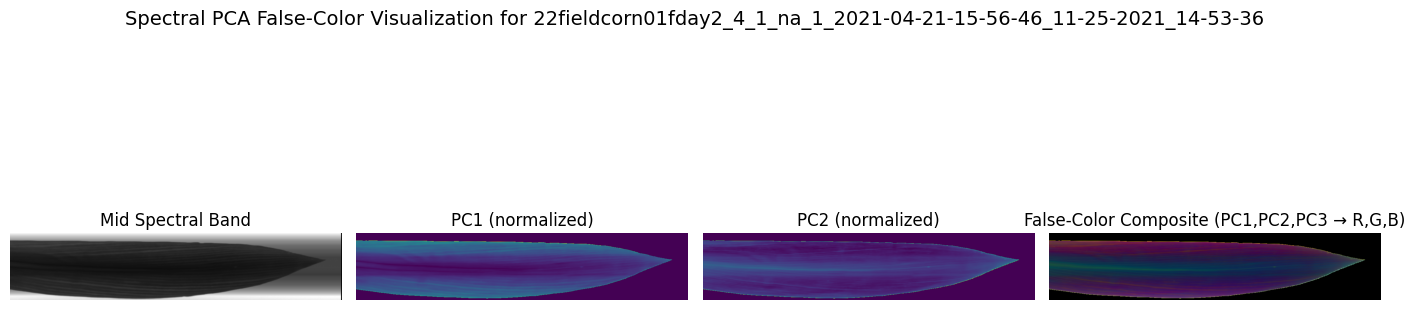

In [22]:
# Step 22: Hyperspectral false-color composite using spectral PCA (PC1, PC2, PC3 → RGB)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Choose example leaf (change index if you like)
example_leaf = gt['file_name'].iloc[0]
print("Using example leaf:", example_leaf)

raw_path = os.path.join(RAW_DIR, example_leaf + ".npz")
seg_path = os.path.join(SEG_DIR, example_leaf + ".npz")

raw_data = np.load(raw_path)
seg_data = np.load(seg_path)

raw_img = raw_data[raw_data.files[0]]    # (H, W, Bands)
mask = seg_data[seg_data.files[0]] > 0   # (H, W)

H, W, B = raw_img.shape
print("Image shape:", raw_img.shape)

# -----------------------------------
# Step 1 — Extract leaf pixels and reshape for PCA
# -----------------------------------
leaf_pixels = raw_img[mask]    # (N_pixels, B)

# Standardize per band (optional but usually good for PCA)
leaf_mean = leaf_pixels.mean(axis=0, keepdims=True)
leaf_std = leaf_pixels.std(axis=0, keepdims=True) + 1e-8
leaf_pixels_norm = (leaf_pixels - leaf_mean) / leaf_std

# -----------------------------------
# Step 2 — PCA across the spectral dimension
# -----------------------------------
pca_spec = PCA(n_components=3)
leaf_pixels_pcs = pca_spec.fit_transform(leaf_pixels_norm)  # (N_pixels, 3)

print("Explained variance (%):", pca_spec.explained_variance_ratio_ * 100)

# -----------------------------------
# Step 3 — Map PC1, PC2, PC3 back to image space
# -----------------------------------
pc_maps = np.zeros((H, W, 3), dtype=float)
for c in range(3):
    temp = np.full((H, W), np.nan)
    temp[mask] = leaf_pixels_pcs[:, c]
    pc_maps[:, :, c] = temp

pc1_map = pc_maps[:, :, 0]
pc2_map = pc_maps[:, :, 1]
pc3_map = pc_maps[:, :, 2]

# -----------------------------------
# Step 4 — Normalize PC maps to 0–1 for display
# -----------------------------------
def norm_to_01(arr, ignore_nan=True):
    a = arr.copy()
    if ignore_nan:
        vals = a[~np.isnan(a)]
    else:
        vals = a.flatten()
    mn, mx = np.min(vals), np.max(vals)
    if mx - mn < 1e-8:
        return np.zeros_like(a)
    out = (a - mn) / (mx - mn)
    out[np.isnan(a)] = 0.0
    return out

pc1_norm = norm_to_01(pc1_map)
pc2_norm = norm_to_01(pc2_map)
pc3_norm = norm_to_01(pc3_map)

# False-color composite: R=PC1, G=PC2, B=PC3
rgb_image = np.stack([pc1_norm, pc2_norm, pc3_norm], axis=-1)

# -----------------------------------
# Step 5 — Plot results
# -----------------------------------
plt.figure(figsize=(14,5))

# Mid-band grayscale
plt.subplot(1,4,1)
mid_band = B // 2
plt.imshow(raw_img[:, :, mid_band], cmap='gray')
plt.title("Mid Spectral Band")
plt.axis('off')

# PC1
plt.subplot(1,4,2)
plt.imshow(pc1_norm, cmap='viridis')
plt.title("PC1 (normalized)")
plt.axis('off')

# PC2
plt.subplot(1,4,3)
plt.imshow(pc2_norm, cmap='viridis')
plt.title("PC2 (normalized)")
plt.axis('off')

# RGB composite
plt.subplot(1,4,4)
plt.imshow(rgb_image)
plt.title("False-Color Composite (PC1,PC2,PC3 → R,G,B)")
plt.axis('off')

plt.suptitle(f"Spectral PCA False-Color Visualization for {example_leaf}", fontsize=14)
plt.tight_layout()
plt.show()


## Step 23 - Pixel Cluster Map from Spectral PCs within a Single Leaf

## Objective

Cluster pixels inside a single leaf based on their spectral principal components and visualize how different spectral groups are spatially distributed.

## Rationale

Even within one leaf, different tissue types or stress zones can have distinct spectral signatures. By compressing spectra into a few principal components and then clustering, we can discover unsupervised “zones” that may correspond to veins, mesophyll, edges, or localized nitrogen patterns without using treatment labels.

## Key Operations

Select one hyperspectral leaf and its segmentation mask.
Extract all leaf pixel spectra and standardize each band.
Apply PCA to reduce the spectra to three principal components per pixel.
Run K-Means clustering on the three-dimensional PC scores to obtain K spectral clusters.
Map cluster IDs back into the leaf image grid using the mask.
Construct a spectral PC false-color composite image using the three PCs.
Plot three views side by side:

1. mid-band grayscale image
2. spectral PCA false-color composite
3. pixel cluster map colored by K-Means cluster ID

## Expected Output

Printed explained variance percentages for the first three PCs.
A figure showing:

* original mid-band leaf image
* spectral PC false-color visualization
* K-Means cluster map, where each color corresponds to a different spectral cluster inside the leaf

Using example leaf: 22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-46_11-25-2021_14-53-36
Image shape: (224, 1111, 364)
Explained variance (%): [85.01865384 11.40379348  1.81530072]


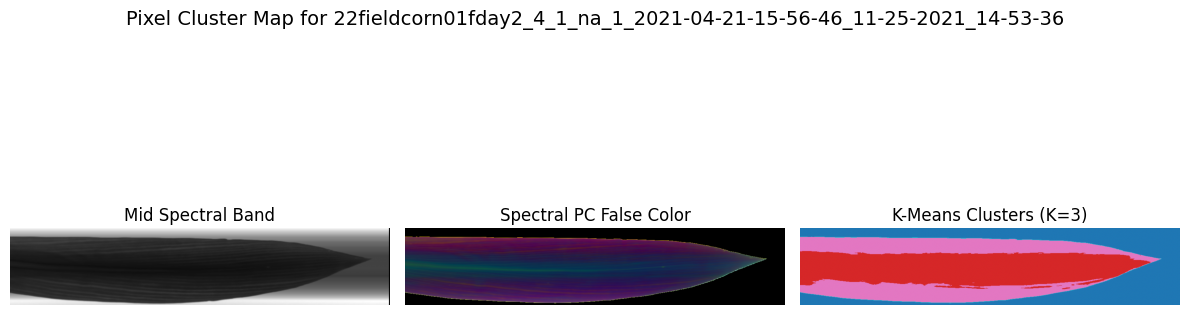

In [23]:
# Step 23: Pixel cluster map (K-Means on spectral PCs within a single leaf)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Choose an example leaf (change index to analyze another)
example_leaf = gt['file_name'].iloc[0]
print("Using example leaf:", example_leaf)

raw_path = os.path.join(RAW_DIR, example_leaf + ".npz")
seg_path = os.path.join(SEG_DIR, example_leaf + ".npz")

raw_data = np.load(raw_path)
seg_data = np.load(seg_path)

raw_img = raw_data[raw_data.files[0]]    # (H, W, Bands)
mask = seg_data[seg_data.files[0]] > 0   # (H, W)

H, W, B = raw_img.shape
print("Image shape:", raw_img.shape)

# -----------------------------------
# Step 1 — Extract leaf pixels & normalize spectra
# -----------------------------------
leaf_pixels = raw_img[mask]   # (N_pixels, B)

# Standardize per band for PCA
leaf_mean = leaf_pixels.mean(axis=0, keepdims=True)
leaf_std = leaf_pixels.std(axis=0, keepdims=True) + 1e-8
leaf_pixels_norm = (leaf_pixels - leaf_mean) / leaf_std

# -----------------------------------
# Step 2 — PCA on spectral dimension (per leaf)
# -----------------------------------
n_pcs = 3
pca_leaf = PCA(n_components=n_pcs)
leaf_pcs = pca_leaf.fit_transform(leaf_pixels_norm)   # (N_pixels, 3)

print("Explained variance (%):", pca_leaf.explained_variance_ratio_ * 100)

# -----------------------------------
# Step 3 — K-Means clustering on PC scores
# -----------------------------------
K = 3   # number of clusters (you can try 2, 3, 4)
kmeans_leaf = KMeans(n_clusters=K, random_state=42)
cluster_ids = kmeans_leaf.fit_predict(leaf_pcs)   # (N_pixels,)

# Map clusters back to image
cluster_map = np.full((H, W), -1, dtype=int)
cluster_map[mask] = cluster_ids

# -----------------------------------
# Step 4 — Plot original and cluster map
# -----------------------------------
plt.figure(figsize=(12,5))

# Mid-band grayscale
plt.subplot(1,3,1)
mid_band = B // 2
plt.imshow(raw_img[:, :, mid_band], cmap='gray')
plt.title("Mid Spectral Band")
plt.axis('off')

# Spectral PC composite (reuse from earlier idea, quickly)
# Normalize PCs
def norm01(a):
    vals = a[~np.isnan(a)]
    mn, mx = vals.min(), vals.max()
    if mx - mn < 1e-8:
        out = np.zeros_like(a)
    else:
        out = (a - mn) / (mx - mn)
    out[np.isnan(a)] = 0
    return out

pc_maps = np.full((H, W, 3), np.nan)
for c in range(3):
    temp = np.full((H, W), np.nan)
    temp[mask] = leaf_pcs[:, c]
    pc_maps[:, :, c] = temp

pc1_norm = norm01(pc_maps[:, :, 0])
pc2_norm = norm01(pc_maps[:, :, 1])
pc3_norm = norm01(pc_maps[:, :, 2])
rgb_pc = np.stack([pc1_norm, pc2_norm, pc3_norm], axis=-1)

plt.subplot(1,3,2)
plt.imshow(rgb_pc)
plt.title("Spectral PC False Color")
plt.axis('off')

# Cluster map
plt.subplot(1,3,3)
plt.imshow(cluster_map, cmap='tab10')
plt.title(f"K-Means Clusters (K={K})")
plt.axis('off')

plt.suptitle(f"Pixel Cluster Map for {example_leaf}", fontsize=14)
plt.tight_layout()
plt.show()


## Step 24 - First-derivative spectra for N1 vs N2

## Objective

Compute and compare the first derivative of leaf mean spectra for N1 and N2 leaves to highlight subtle differences in spectral shape, especially around red-edge and chlorophyll absorption regions.

## Rationale

Raw reflectance spectra can look very similar between treatments, but the slope (rate of change with wavelength) often shows clearer separation, particularly near steep transitions like the red edge. First-derivative spectra emphasize these slope differences and are commonly used in hyperspectral analysis of stress and nutrient status.

## What this cell does

Collects mean spectra for each leaf by averaging all leaf pixels over the full spectral range.
Ensures a global wavelength array exists, computing it from the first file if needed.
Builds a leaf_spectra matrix with one row per leaf and one column per band, and a corresponding label vector (N1 or N2).
Computes the first derivative of reflectance with respect to wavelength using finite differences (diff in reflectance divided by diff in wavelength) and defines mid-wavelengths for plotting.
Separates derivative spectra into N1 and N2 groups.
Computes mean and standard deviation derivative spectra for N1 and N2.
Plots mean first-derivative spectra for both treatments with shaded ±1 standard deviation envelopes.

## Expected output

Printed shape of the leaf_spectra matrix (number of leaves and bands).
A line plot of mean d(Reflectance)/dλ for N1 and N2 as functions of wavelength, with shaded variability bands, showing where slope differences between treatments are strongest.


Leaf spectra matrix shape: (40, 364)


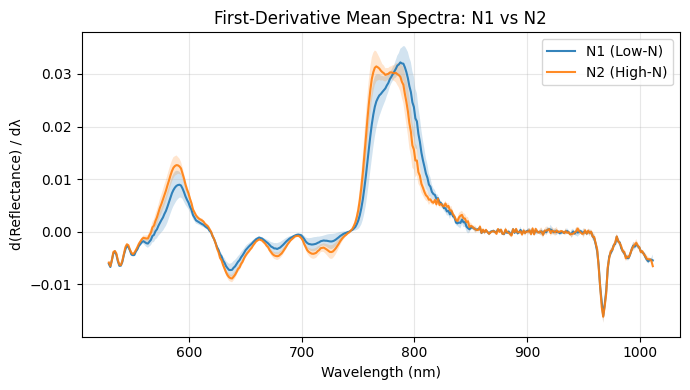

In [24]:
# Step 24: First-derivative spectra for N1 vs N2

import numpy as np
import matplotlib.pyplot as plt

# Safety check: ensure we have global wavelengths
if wavelengths_global is None:
    # Recompute from first raw file if needed
    any_file = gt['file_name'].iloc[0]
    raw_path_any = os.path.join(RAW_DIR, any_file + ".npz")
    raw_data_any = np.load(raw_path_any)
    raw_img_any = raw_data_any[raw_data_any.files[0]]
    num_bands_any = raw_img_any.shape[2]
    wavelengths_global = np.array([band_to_wavelength(b) for b in range(num_bands_any)])

# Containers
leaf_spectra = []     # shape: (n_leaves, n_bands)
leaf_labels  = []     # N1 / N2

print("Collecting mean spectra per leaf for derivative analysis...")

for idx, row in gt.iterrows():
    file_name = row["file_name"]
    treatment = row["treatment"]

    raw_path = os.path.join(RAW_DIR, file_name + ".npz")
    seg_path = os.path.join(SEG_DIR, file_name + ".npz")

    if not (os.path.exists(raw_path) and os.path.exists(seg_path)):
        continue

    raw_data = np.load(raw_path)
    seg_data = np.load(seg_path)

    raw_img = raw_data[raw_data.files[0]]     # (H, W, Bands)
    mask = seg_data[seg_data.files[0]] > 0    # (H, W)

    if mask.sum() == 0:
        continue

    leaf_pixels = raw_img[mask]              # (N_pixels, Bands)
    mean_spectrum = leaf_pixels.mean(axis=0) # (Bands,)

    leaf_spectra.append(mean_spectrum)
    leaf_labels.append(treatment)

leaf_spectra = np.vstack(leaf_spectra)       # (n_leaves, n_bands)
leaf_labels = np.array(leaf_labels)

print("Leaf spectra matrix shape:", leaf_spectra.shape)

# ---- Compute first derivative along wavelength ----
# central difference approx: derivative wrt wavelength
wv = wavelengths_global
# to avoid issues if wv not strictly uniform, use np.diff / np.diff
d_reflectance = np.diff(leaf_spectra, axis=1)
d_wv = np.diff(wv)

deriv_spectra = d_reflectance / d_wv  # (n_leaves, n_bands-1)
wv_mid = (wv[:-1] + wv[1:]) / 2       # midpoints for plotting

# ---- Separate N1 and N2 ----
mask_N1 = (leaf_labels == "N1")
mask_N2 = (leaf_labels == "N2")

deriv_N1 = deriv_spectra[mask_N1]
deriv_N2 = deriv_spectra[mask_N2]

mean_deriv_N1 = deriv_N1.mean(axis=0)
std_deriv_N1  = deriv_N1.std(axis=0)

mean_deriv_N2 = deriv_N2.mean(axis=0)
std_deriv_N2  = deriv_N2.std(axis=0)

# ---- Plot mean first-derivative spectra ----
plt.figure(figsize=(7,4))

plt.plot(wv_mid, mean_deriv_N1, label="N1 (Low-N)", alpha=0.9)
plt.fill_between(wv_mid,
                 mean_deriv_N1 - std_deriv_N1,
                 mean_deriv_N1 + std_deriv_N1,
                 alpha=0.2)

plt.plot(wv_mid, mean_deriv_N2, label="N2 (High-N)", alpha=0.9)
plt.fill_between(wv_mid,
                 mean_deriv_N2 - std_deriv_N2,
                 mean_deriv_N2 + std_deriv_N2,
                 alpha=0.2)

plt.xlabel("Wavelength (nm)")
plt.ylabel("d(Reflectance) / dλ")
plt.title("First-Derivative Mean Spectra: N1 vs N2")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Step 25 - Tiny Autoencoder for Nonlinear Spectral Compression

## Objective

Learn a compact nonlinear representation of pixel-level hyperspectral spectra using a small autoencoder and visualize how N1 and N2 pixels are arranged in this latent space.

## Rationale

PCA gives a linear compression of spectra, but real plant spectral responses can be nonlinear. An autoencoder can learn a nonlinear mapping that may separate nitrogen treatments more clearly in a low-dimensional latent space. This is an “advanced/bonus” step that shows you explored deep-learning-based feature learning.

## Key Operations

Prepare the pixel dataset by reusing pixel_spectra_all and normalizing each band (subtract mean and divide by standard deviation).
Convert normalized spectra to a PyTorch tensor for model training.
Define a small fully connected autoencoder with
encoder: input → 64 → 16 → latent_dim (3)
decoder: latent_dim → 16 → 64 → input
Train the autoencoder using mean squared error between input and reconstructed spectra for a small number of epochs and mini-batches.
After training, pass all pixels through the encoder to obtain latent codes Z with shape (number of pixels, 3).
Plot the 3D latent space (Z1, Z2, Z3) and color points by their nitrogen label (N1 or N2) to visually inspect any separation.

## Expected Output

Printed training data shape and epoch-wise reconstruction loss values showing convergence.
Printed latent space shape after encoding.
A 3D scatter plot where each point is a pixel in the autoencoder latent space, colored by N1 vs N2, revealing whether the nonlinear embedding groups nitrogen treatments into distinct regions.

Autoencoder training data: torch.Size([24000, 364])
Epoch 1/20  Loss = 36.3853
Epoch 2/20  Loss = 4.3729
Epoch 3/20  Loss = 2.0951
Epoch 4/20  Loss = 1.4830
Epoch 5/20  Loss = 1.2720
Epoch 6/20  Loss = 1.1255
Epoch 7/20  Loss = 1.0393
Epoch 8/20  Loss = 0.9808
Epoch 9/20  Loss = 0.9046
Epoch 10/20  Loss = 0.8631
Epoch 11/20  Loss = 0.8227
Epoch 12/20  Loss = 0.8013
Epoch 13/20  Loss = 0.7678
Epoch 14/20  Loss = 0.7453
Epoch 15/20  Loss = 0.7250
Epoch 16/20  Loss = 0.7195
Epoch 17/20  Loss = 0.7109
Epoch 18/20  Loss = 0.6935
Epoch 19/20  Loss = 0.6723
Epoch 20/20  Loss = 0.6698
Autoencoder training completed.
Latent space shape: (24000, 3)


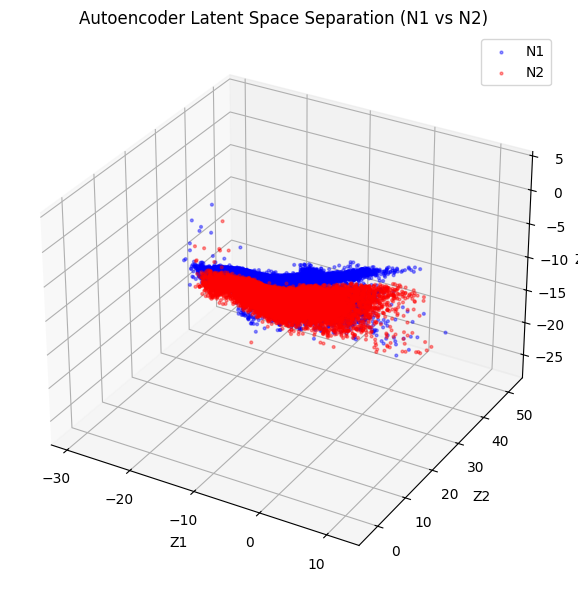

In [25]:
# Step 25: Tiny Autoencoder for nonlinear spectral compression

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# --------------------------------------------------
# Step 1 — Prepare pixel spectra dataset
# --------------------------------------------------

# Reuse pixel_spectra_all collected earlier
X_ae = pixel_spectra_all.astype(np.float32)

# Normalize spectra band-wise (same as PCA step)
mean_ae = X_ae.mean(axis=0, keepdims=True)
std_ae = X_ae.std(axis=0, keepdims=True) + 1e-8
X_ae_norm = (X_ae - mean_ae) / std_ae

# Convert to torch tensors
X_tensor = torch.tensor(X_ae_norm)

print("Autoencoder training data:", X_tensor.shape)

# --------------------------------------------------
# Step 2 — Define a tiny autoencoder
# --------------------------------------------------
class Autoencoder(nn.Module):
    def __init__(self, input_dim=364, latent_dim=3):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 16),
            nn.ReLU(),
            nn.Linear(16, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 64),
            nn.ReLU(),
            nn.Linear(64, input_dim)
        )
    def forward(self, x):
        z = self.encoder(x)
        out = self.decoder(z)
        return out, z

latent_dim = 3
model = Autoencoder(input_dim=X_tensor.shape[1], latent_dim=latent_dim)

optimizer = optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

# --------------------------------------------------
# Step 3 — Train autoencoder
# --------------------------------------------------
epochs = 20    # keep small for fast training
batch_size = 256

model.train()
for epoch in range(epochs):
    perm = torch.randperm(X_tensor.size(0))
    epoch_loss = 0
    for i in range(0, X_tensor.size(0), batch_size):
        idx = perm[i : i + batch_size]
        batch = X_tensor[idx]

        optimizer.zero_grad()
        recon, _ = model(batch)
        loss = criterion(recon, batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs}  Loss = {epoch_loss:.4f}")

print("Autoencoder training completed.")

# --------------------------------------------------
# Step 4 — Extract latent representations (Z)
# --------------------------------------------------
model.eval()
with torch.no_grad():
    _, Z = model(X_tensor)
Z = Z.numpy()      # (N_pixels, latent_dim)

print("Latent space shape:", Z.shape)

# --------------------------------------------------
# Step 5 — Visualize latent space clusters (3D)
# --------------------------------------------------
from mpl_toolkits.mplot3d import Axes3D

labels_px = pixel_labels_all  # "N1" or "N2"

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')

mask_N1 = (labels_px == "N1")
mask_N2 = (labels_px == "N2")

ax.scatter(Z[mask_N1,0], Z[mask_N1,1], Z[mask_N1,2],
           s=4, alpha=0.4, label='N1', color='blue')
ax.scatter(Z[mask_N2,0], Z[mask_N2,1], Z[mask_N2,2],
           s=4, alpha=0.4, label='N2', color='red')

ax.set_xlabel("Z1")
ax.set_ylabel("Z2")
ax.set_zlabel("Z3")
ax.set_title("Autoencoder Latent Space Separation (N1 vs N2)")
plt.legend()
plt.tight_layout()
plt.show()


## Step 26 - Region-wise feature extraction using anatomical masks

## Objective

Summarize spectral and nitrogen-related features separately for each anatomical leaf region (leaf, veins, midrib, mesophyll, edge, tip, clean leaf) across all leaves.

## Rationale

Your professor’s segmentation masks divide each leaf into biologically meaningful regions. Instead of treating the leaf as a single object, this step builds a region-level dataset that links anatomy, spectral signatures, classical indices, and model-based nitrogen probability. This is powerful for explaining where nitrogen differences are most pronounced (for example, veins vs mesophyll, tip vs rest, etc.).

## Key operations

Loop over all leaves listed in the metadata table.
For each leaf:

* Load the hyperspectral cube and the segmentation npz with multiple masks.
* Compute a pixel-level nitrogen probability map using the trained scaler, PCA model, and pixel classifier, restricted to the leaf mask.
* Compute NDVI and OCAR maps from selected bands (around 680 nm, 800 nm, and 630 nm).
  Then, for each anatomical mask name you specify (leaf_mask, vein_mask, rib or midrib, mesophyll, leaf_edge_mask, leaf_tip_mask, cln_leaf_mask):
* Check that the mask exists and has nonzero pixels.
* Extract all spectral pixels from that region.
* Compute:

  * mean reflectance spectrum of that region
  * mean NDVI over that region
  * mean OCAR over that region
  * mean N2 probability (from the ML model) over that region
* Sample region reflectance at a few biologically relevant wavelengths (for example 550, 630, 680, 800 nm) and store them as R_550, R_630, R_680, R_800.
  Append one row per leaf–region–treatment combination into a list and finally convert it into a DataFrame called df_region.

## Expected output

A tidy region-level table where each row contains
leaf identifier
treatment (N1 or N2)
region name (leaf_mask, vein_mask, meso_mask, leaf_tip_mask, etc.)
mean_N2_prob (average pixel-level nitrogen probability in that region)
mean_NDVI and mean_OCAR
sampled reflectances at key wavelengths for that region

This table can be used later for boxplots, ANOVA, or region-wise visualizations comparing N1 vs N2.

In [26]:
# Step 26: Region-wise feature extraction using professor-provided masks

import numpy as np
import pandas as pd
import os

leaf_region_features = []

for idx, row in gt.iterrows():
    file_name = row["file_name"]
    treatment = row["treatment"]

    raw_path = os.path.join(RAW_DIR, file_name + ".npz")
    seg_path = os.path.join(SEG_DIR, file_name + ".npz")

    if not (os.path.exists(raw_path) and os.path.exists(seg_path)):
        print("Skipping:", file_name)
        continue

    raw_data = np.load(raw_path)
    seg_data = np.load(seg_path)

    raw_img = raw_data[raw_data.files[0]]   # (H, W, Bands)
    masks = seg_data.files
    H, W, B = raw_img.shape

    # Compute NDVI/OCAR full maps first
    leaf_pixels = raw_img[seg_data["leaf_mask"] > 0]
    leaf_pixels_scaled = scaler_model.transform(leaf_pixels)
    leaf_pcs = pca_model.transform(leaf_pixels_scaled)
    pixel_probs = pixel_classifier.predict_proba(leaf_pcs)[:,1]

    # reconstruct nitrogen prob map (optional)
    prob_map = np.full((H, W), np.nan)
    prob_map[seg_data["leaf_mask"] > 0] = pixel_probs

    # compute index maps
    band_680 = np.argmin(np.abs(wavelengths_global - 680))
    band_800 = np.argmin(np.abs(wavelengths_global - 800))
    band_630 = np.argmin(np.abs(wavelengths_global - 630))

    ndvi_map = (raw_img[:,:,band_800] - raw_img[:,:,band_680]) / (raw_img[:,:,band_800] + raw_img[:,:,band_680] + 1e-8)
    ocar_map = (raw_img[:,:,band_630] - raw_img[:,:,band_680]) / (raw_img[:,:,band_630] + raw_img[:,:,band_680] + 1e-8)

    # Now extract features region-wise
    for mask_name in ["leaf_mask", "vein_mask", "rib_mask", "meso_mask", "leaf_edge_mask", "leaf_tip_mask", "cln_leaf_mask"]:
        if mask_name not in masks:
            continue

        mask_region = seg_data[mask_name] > 0
        if mask_region.sum() == 0:
            continue

        region_pixels = raw_img[mask_region]  # (N_region_pixels, Bands)

        mean_spec = region_pixels.mean(axis=0)
        mean_ndvi = np.nanmean(ndvi_map[mask_region])
        mean_ocar = np.nanmean(ocar_map[mask_region])

        leaf_region_features.append({
            "leaf": file_name,
            "treatment": treatment,
            "region": mask_name,
            "mean_N2_prob": np.nanmean(prob_map[mask_region]),
            "mean_NDVI": mean_ndvi,
            "mean_OCAR": mean_ocar,
            **{f"R_{int(wv)}": mean_spec[np.argmin(np.abs(wavelengths_global - wv))]
               for wv in [550, 630, 680, 800]}
        })

# Convert to DataFrame
df_region = pd.DataFrame(leaf_region_features)
df_region


,leaf,treatment,region,mean_N2_prob,mean_NDVI,mean_OCAR,R_550,R_630,R_680,R_800
0,22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-4...,N1,leaf_mask,0.644264,0.691367,0.325490,0.267007,0.514138,0.269239,1.408893
1,22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-4...,N1,vein_mask,0.547657,0.711489,0.329465,0.248110,0.462966,0.235314,1.372922
2,22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-4...,N1,meso_mask,0.674489,0.685072,0.324246,0.272919,0.530148,0.279852,1.420148
3,22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-4...,N1,leaf_edge_mask,0.756350,0.612333,0.274638,0.423859,0.734111,0.429208,1.737911
4,22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-4...,N1,leaf_tip_mask,0.662172,0.608044,0.275947,0.349632,0.529805,0.308245,1.231952
...,...,...,...,...,...,...,...,...,...,...
235,22fieldcorn01fday2_6_3_na_2_2021-04-21-16-08-1...,N2,vein_mask,0.736264,0.647377,0.290211,0.243363,0.510177,0.281325,1.313102
236,22fieldcorn01fday2_6_3_na_2_2021-04-21-16-08-1...,N2,meso_mask,0.766017,0.637632,0.294981,0.277987,0.566646,0.315432,1.383521
237,22fieldcorn01fday2_6_3_na_2_2021-04-21-16-08-1...,N2,leaf_edge_mask,0.767947,0.575024,0.259570,0.404650,0.761347,0.456853,1.664225
238,22fieldcorn01fday2_6_3_na_2_2021-04-21-16-08-1...,N2,leaf_tip_mask,0.688244,0.525842,0.233240,0.367229,0.612229,0.388292,1.220865


In [27]:
print(df_region.head())
print(df_region['region'].value_counts())


                                                leaf treatment  \
0  22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-4...        N1   
1  22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-4...        N1   
2  22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-4...        N1   
3  22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-4...        N1   
4  22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-4...        N1   

           region  mean_N2_prob  mean_NDVI  mean_OCAR     R_550     R_630  \
0       leaf_mask      0.644264   0.691367   0.325490  0.267007  0.514138   
1       vein_mask      0.547657   0.711489   0.329465  0.248110  0.462966   
2       meso_mask      0.674489   0.685072   0.324246  0.272919  0.530148   
3  leaf_edge_mask      0.756350   0.612333   0.274638  0.423859  0.734111   
4   leaf_tip_mask      0.662172   0.608044   0.275947  0.349632  0.529805   

      R_680     R_800  
0  0.269239  1.408893  
1  0.235314  1.372922  
2  0.279852  1.420148  
3  0.429208  1.737911  
4  0.308245  1.23195

## Step 27 - Region-Level NDVI Treatment Comparison

## Objective

Evaluate whether nitrogen treatments (N1 vs N2) show statistically different NDVI behavior **within each anatomical region** using boxplots and Welch’s t-test.

## Rationale

Earlier you transformed raw hyperspectral data into a region-wise feature table. Now you treat **each region independently** to check if NDVI values for N1 and N2 leaves differ in that specific leaf zone. Using Welch’s t-test is logical because class sizes and variances can be unequal.

## Key Steps in this Cell

* Use the existing `df_region` table where each row represents one (leaf, region) pair.
* Print total region-leaf samples and preview the first rows for sanity.
* Get the list of unique regions present in the table.
* For each region:

  * Create a subset containing only that region’s pixels from all leaves.
  * Split leaf samples into treatment groups N1 and N2.
  * Compute Welch t-test on mean NDVI values.
  * Plot a 2-group boxplot (N1 vs N2) and annotate the p-value in the plot title.
  * Print the region name with t-statistic and p-value.

## Expected Output You Should See

A loop of figures where each region panel shows:

* A boxplot with two distributions (N1 left, N2 right).
* A p-value telling if the region shows significant nitrogen response in NDVI.
  Printed summary lines like:
  region name NDVI t-stat value, p value

This helps a reader understand *which anatomical zones are sensitive to nitrogen according to NDVI*.

Total samples (region-leaf pairs): 240
                                                leaf treatment  \
0  22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-4...        N1   
1  22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-4...        N1   
2  22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-4...        N1   
3  22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-4...        N1   
4  22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-4...        N1   

           region  mean_N2_prob  mean_NDVI  mean_OCAR     R_550     R_630  \
0       leaf_mask      0.644264   0.691367   0.325490  0.267007  0.514138   
1       vein_mask      0.547657   0.711489   0.329465  0.248110  0.462966   
2       meso_mask      0.674489   0.685072   0.324246  0.272919  0.530148   
3  leaf_edge_mask      0.756350   0.612333   0.274638  0.423859  0.734111   
4   leaf_tip_mask      0.662172   0.608044   0.275947  0.349632  0.529805   

      R_680     R_800  
0  0.269239  1.408893  
1  0.235314  1.372922  
2  0.279852  1.420148  
3  0.

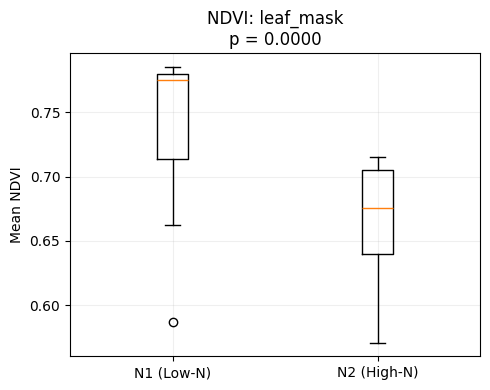

[leaf_mask] NDVI t-stat = 4.972, p-value = 0.0000


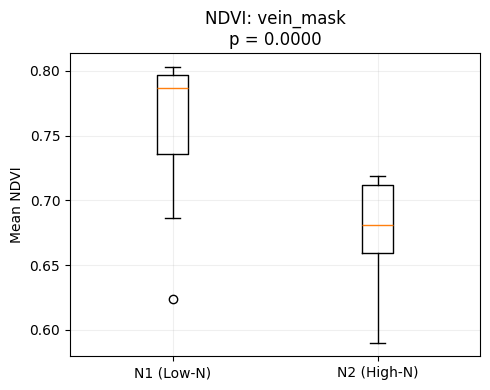

[vein_mask] NDVI t-stat = 6.100, p-value = 0.0000


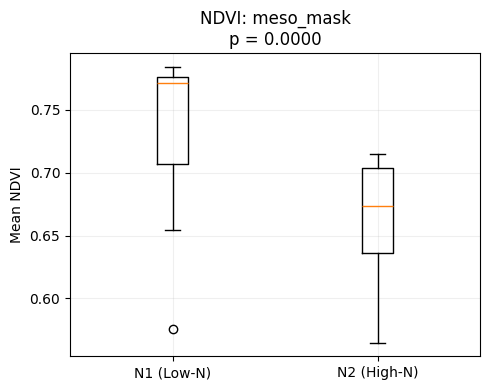

[meso_mask] NDVI t-stat = 4.670, p-value = 0.0000


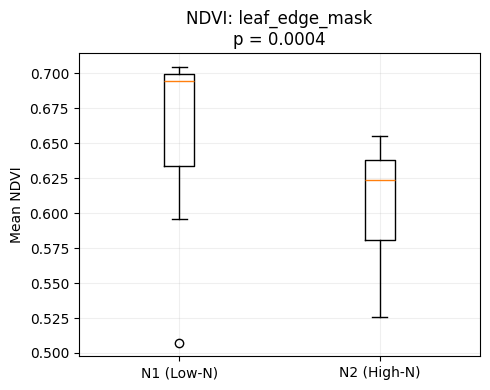

[leaf_edge_mask] NDVI t-stat = 3.917, p-value = 0.0004


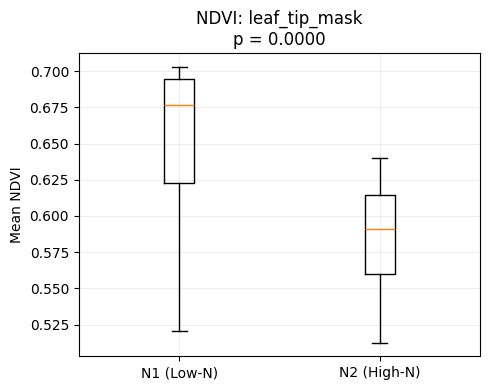

[leaf_tip_mask] NDVI t-stat = 5.165, p-value = 0.0000


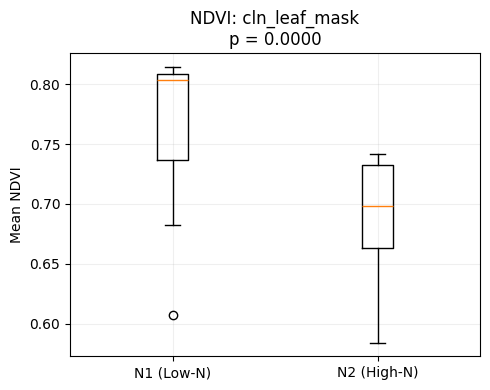

[cln_leaf_mask] NDVI t-stat = 4.883, p-value = 0.0000


In [28]:
# Step 27: Group-level statistics per region (mask zone) for N1 vs N2 leaves

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

df = df_region  # Your structured region-wise feature table

print("Total samples (region-leaf pairs):", len(df))
print(df.head(), "\n")

regions = df["region"].unique()

for region in regions:
    sub = df[df["region"] == region]

    N1 = sub[sub["treatment"] == "N1"]
    N2 = sub[sub["treatment"] == "N2"]

    # Run Welch t-test for NDVI in this region
    t_stat, p_val = ttest_ind(N1["mean_NDVI"], N2["mean_NDVI"], equal_var=False)

    # Boxplot
    plt.figure(figsize=(5,4))
    plt.boxplot([N1["mean_NDVI"], N2["mean_NDVI"]])
    plt.xticks([1,2], ["N1 (Low-N)", "N2 (High-N)"])
    plt.ylabel("Mean NDVI")
    plt.title(f"NDVI: {region}\np = {p_val:.4f}")
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

    print(f"[{region}] NDVI t-stat = {t_stat:.3f}, p-value = {p_val:.4f}")



## Step 28 - Region-Level OCAR Treatment Comparison

## Objective

Compare OCAR values between nitrogen treatments (N1 vs N2) **for each leaf anatomical region** using boxplots and Welch’s t-test.

## Rationale

OCAR tracks chlorophyll absorption changes, which correlate with nitrogen level. This step checks if **high vs low nitrogen leaves show measurable differences in OCAR scores inside each specific leaf region**, providing interpretable, region-sensitive statistics.

## What this cell does

* Uses the prebuilt region-wise table (`df_region`) where each row represents one leaf-region sample.
* Gets unique anatomical regions present in the dataset.
* For each region:

  * Creates a subset of leaf samples belonging to that region.
  * Splits them into N1 (low nitrogen) and N2 (high nitrogen).
  * Runs Welch’s t-test to compare mean OCAR values safely under unequal variance.
  * Plots a two-group boxplot (N1 vs N2) for that region.
  * Prints region name, t-stat, and p-value.

## Expected output

For each anatomical region:

* A boxplot showing OCAR distribution for N1 (left) vs N2 (right).
* A p-value indicating if that region differentiates nitrogen levels via OCAR.
  This highlights **which leaf zones exhibit strong nitrogen sensitivity** for chlorophyll absorption patterns.


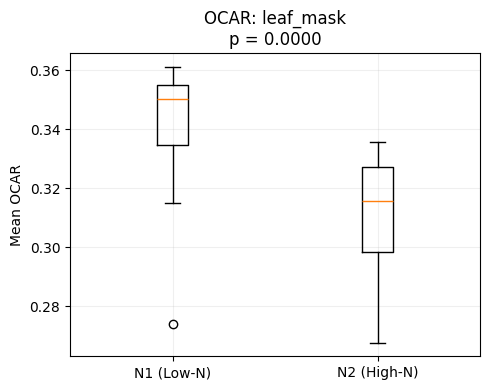

[leaf_mask] OCAR t-stat = 4.980, p-value = 0.0000


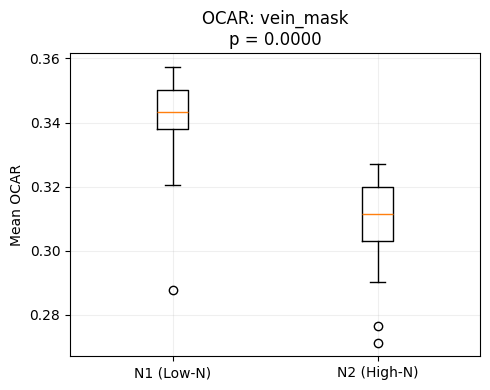

[vein_mask] OCAR t-stat = 6.770, p-value = 0.0000


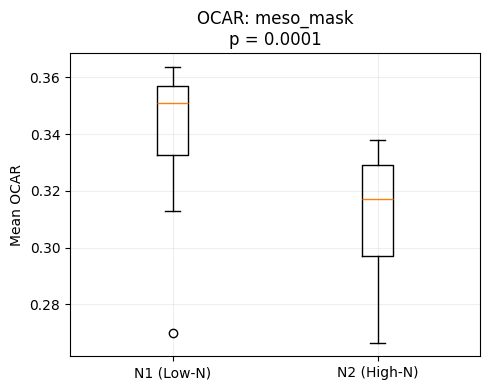

[meso_mask] OCAR t-stat = 4.569, p-value = 0.0001


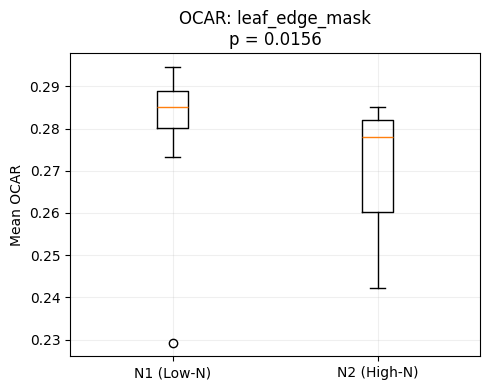

[leaf_edge_mask] OCAR t-stat = 2.533, p-value = 0.0156


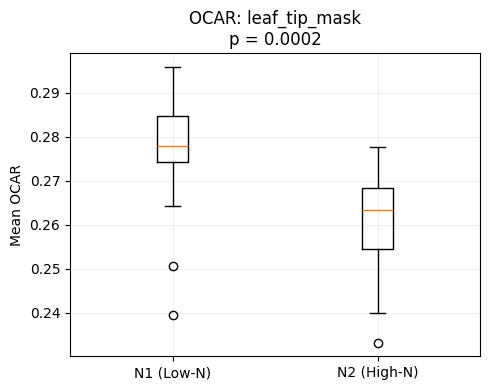

[leaf_tip_mask] OCAR t-stat = 4.128, p-value = 0.0002


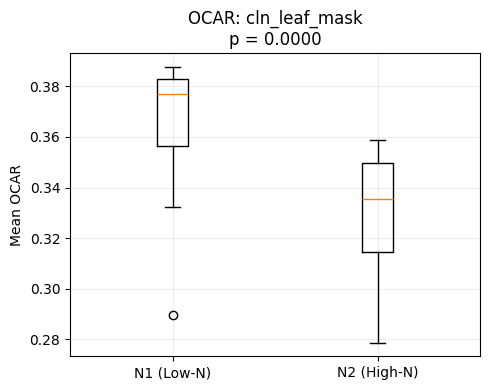

[cln_leaf_mask] OCAR t-stat = 4.928, p-value = 0.0000


In [29]:
# Step 28: Group-level statistics for OCAR (N1 vs N2) per mask-defined region

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

df = df_region  # Your structured region-wise table
regions = df["region"].unique()

for region in regions:
    sub = df[df["region"] == region]

    N1 = sub[sub["treatment"] == "N1"]
    N2 = sub[sub["treatment"] == "N2"]

    # Welch’s t-test for OCAR
    t_stat, p_val = ttest_ind(N1["mean_OCAR"], N2["mean_OCAR"], equal_var=False)

    # Boxplot
    plt.figure(figsize=(5,4))
    plt.boxplot([N1["mean_OCAR"], N2["mean_OCAR"]])
    plt.xticks([1,2], ["N1 (Low-N)", "N2 (High-N)"])
    plt.ylabel("Mean OCAR")
    plt.title(f"OCAR: {region}\np = {p_val:.4f}")
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

    print(f"[{region}] OCAR t-stat = {t_stat:.3f}, p-value = {p_val:.4f}")


## Step 29 - Region-Level Reflectance Treatment Comparison

## Objective

Statistically compare selected reflectance bands (550, 630, 680, 800 nm) between nitrogen treatments (N1 vs N2) **for each anatomical region**.

## Rationale

Individual wavelength reflectance changes due to nitrogen-driven chlorophyll and internal leaf physiology. This cell verifies whether **specific spectral bands alone** can distinguish high-nitrogen vs low-nitrogen leaves when evaluated region-wise.

## What this cell does

* Uses `df_region`, where each row = (leaf, region) sample.
* Identifies unique anatomical `regions`.
* For each region and each reflectance band (`R_550`, `R_630`, `R_680`, `R_800`):

  * Splits samples by treatment.
  * Applies Welch’s t-test under unequal variance.
  * Generates a 2-group boxplot (N1 left, N2 right).
  * Prints a treatment comparison summary for every region-band pair.

## Expected output

A sequence of boxplots for each region-band pair, plus printed lines:
region | band | t-stat | p-value
These results show **which wavelengths are most treatment-responsive in each leaf zone**.

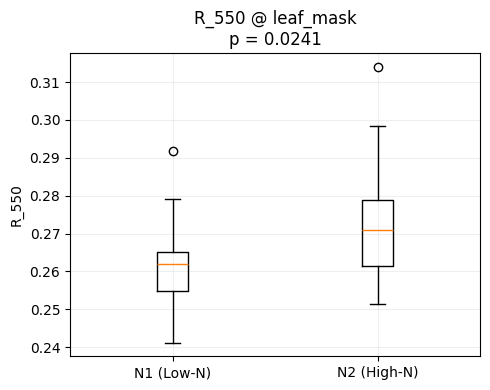

[leaf_mask | R_550] t-stat = -2.353, p = 0.0241


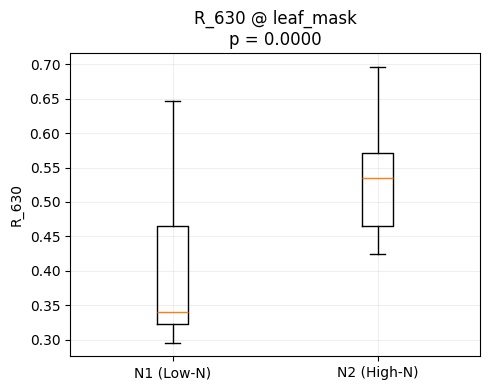

[leaf_mask | R_630] t-stat = -4.805, p = 0.0000


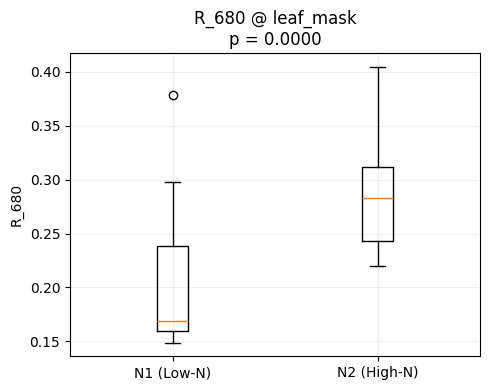

[leaf_mask | R_680] t-stat = -4.619, p = 0.0000


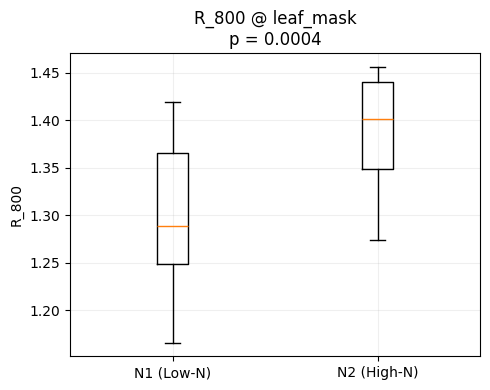

[leaf_mask | R_800] t-stat = -3.975, p = 0.0004


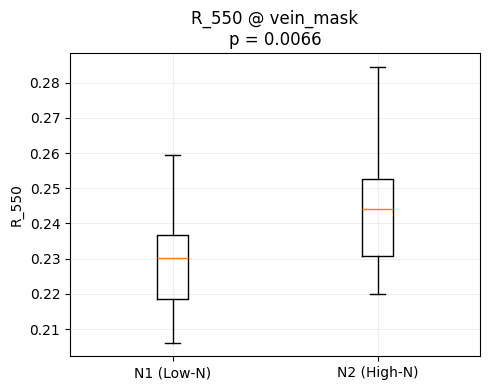

[vein_mask | R_550] t-stat = -2.877, p = 0.0066


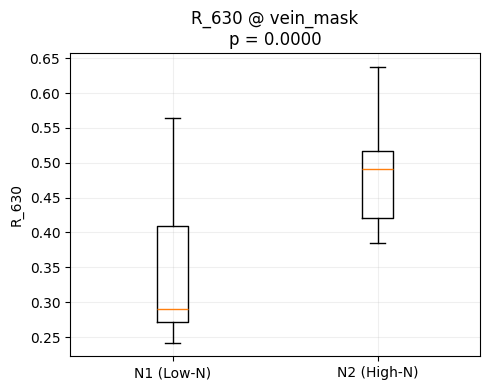

[vein_mask | R_630] t-stat = -5.376, p = 0.0000


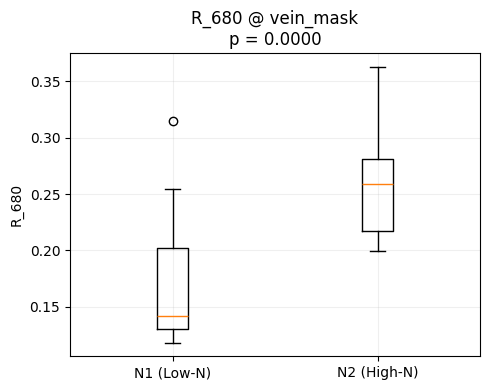

[vein_mask | R_680] t-stat = -5.473, p = 0.0000


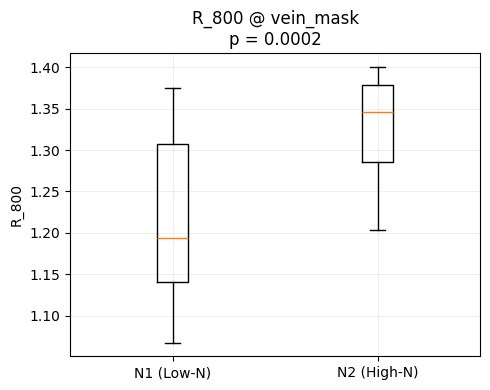

[vein_mask | R_800] t-stat = -4.152, p = 0.0002


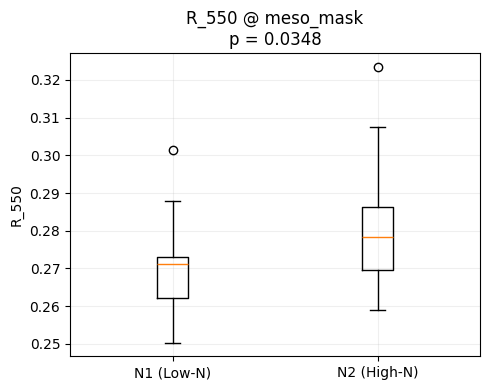

[meso_mask | R_550] t-stat = -2.193, p = 0.0348


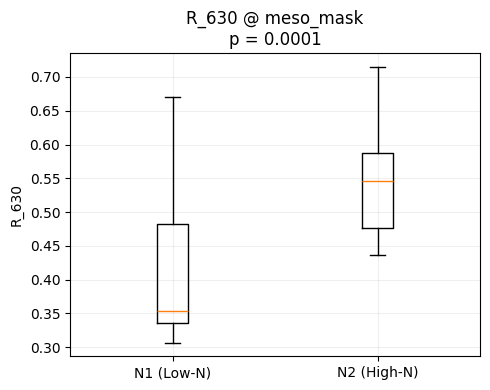

[meso_mask | R_630] t-stat = -4.613, p = 0.0001


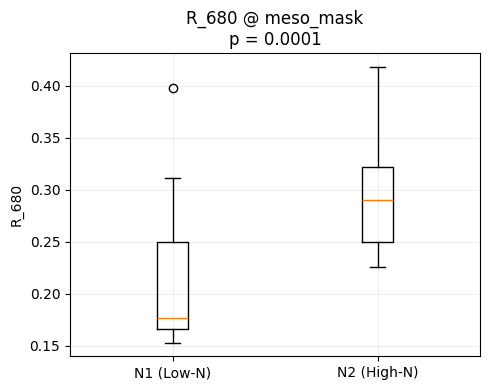

[meso_mask | R_680] t-stat = -4.374, p = 0.0001


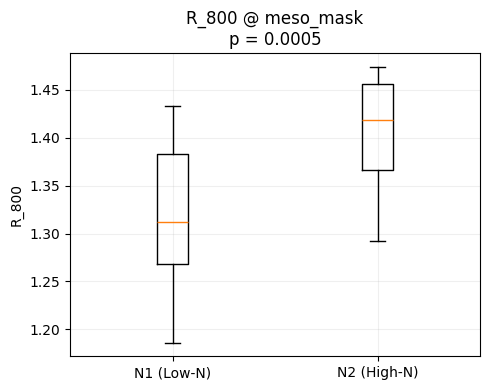

[meso_mask | R_800] t-stat = -3.867, p = 0.0005


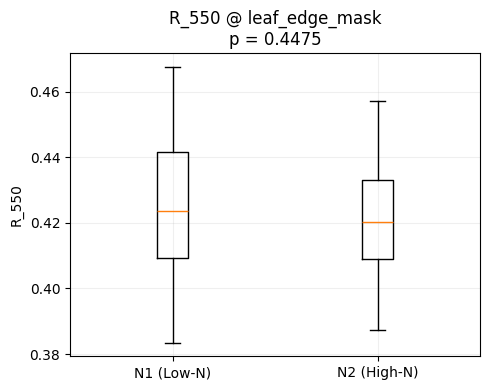

[leaf_edge_mask | R_550] t-stat = 0.768, p = 0.4475


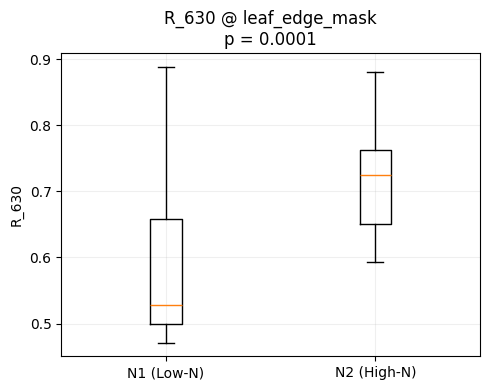

[leaf_edge_mask | R_630] t-stat = -4.316, p = 0.0001


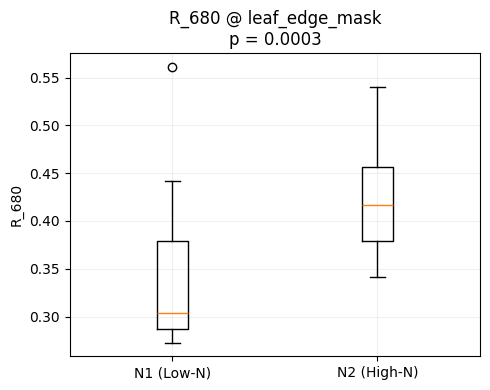

[leaf_edge_mask | R_680] t-stat = -4.032, p = 0.0003


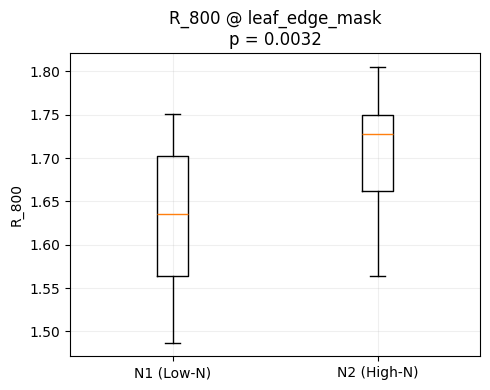

[leaf_edge_mask | R_800] t-stat = -3.165, p = 0.0032


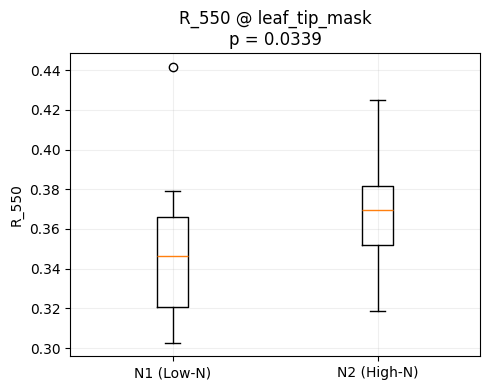

[leaf_tip_mask | R_550] t-stat = -2.203, p = 0.0339


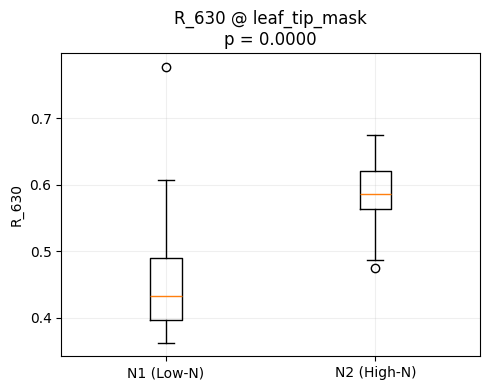

[leaf_tip_mask | R_630] t-stat = -4.741, p = 0.0000


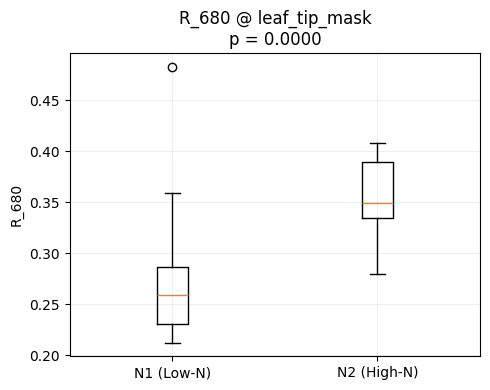

[leaf_tip_mask | R_680] t-stat = -4.772, p = 0.0000


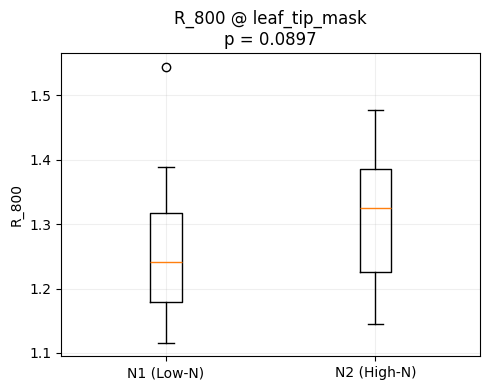

[leaf_tip_mask | R_800] t-stat = -1.742, p = 0.0897


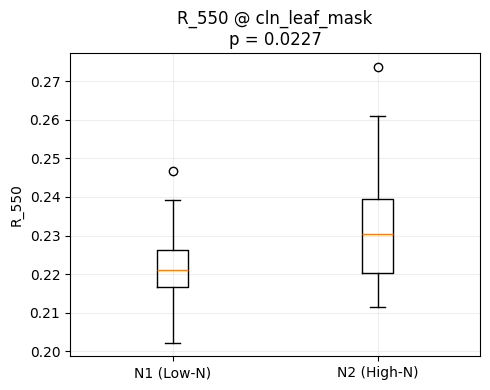

[cln_leaf_mask | R_550] t-stat = -2.381, p = 0.0227


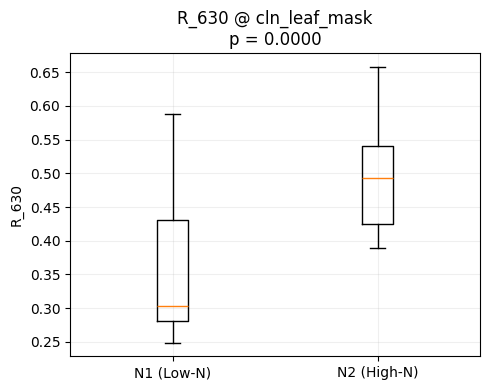

[cln_leaf_mask | R_630] t-stat = -4.850, p = 0.0000


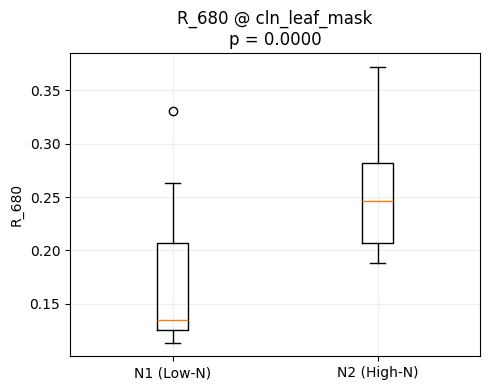

[cln_leaf_mask | R_680] t-stat = -4.629, p = 0.0000


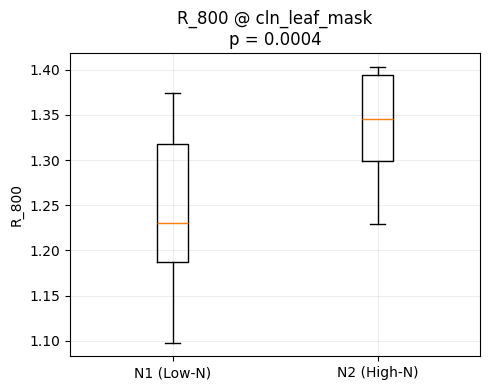

[cln_leaf_mask | R_800] t-stat = -3.949, p = 0.0004


In [30]:
# Step 29: Group-level statistics for reflectance bands (550, 630, 680, 800 nm) per region

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

df = df_region
regions = df["region"].unique()
bands = ["R_550", "R_630", "R_680", "R_800"]

for region in regions:
    sub = df[df["region"] == region]
    N1 = sub[sub["treatment"] == "N1"]
    N2 = sub[sub["treatment"] == "N2"]

    for band in bands:
        t_stat, p_val = ttest_ind(N1[band], N2[band], equal_var=False)

        plt.figure(figsize=(5,4))
        plt.boxplot([N1[band], N2[band]])
        plt.xticks([1,2], ["N1 (Low-N)", "N2 (High-N)"])
        plt.ylabel(band)
        plt.title(f"{band} @ {region}\np = {p_val:.4f}")
        plt.grid(alpha=0.2)
        plt.tight_layout()
        plt.show()

        print(f"[{region} | {band}] t-stat = {t_stat:.3f}, p = {p_val:.4f}")


## Step 30 - ANOVA: Global Feature Comparison Between Nitrogen Groups

## Objective

Compare leaf samples across nitrogen treatments (N1 vs N2) using **ANOVA on region-level collapsed features** to check which features differ significantly at the population level.

## Rationale

You already performed region-wise comparison using boxplots and t-tests. This cell now summarizes a **group-level significance test for raw reflectance and spectral indices**, giving a quick numeric view of treatment separation across all leaves.

## What this cell is doing

* Defines a list of final chosen features:
  `mean_NDVI`, `mean_OCAR`, `R_550`, `R_630`, `R_680`, `R_800`
* For each feature:

  * Removes NaN samples
  * Splits remaining values into nitrogen groups
  * Runs a 1-way ANOVA test if both groups have more than 1 sample
  * Stores F-statistic and p-value
* Converts results into a summary table (`df_anova`)
* Prints that table

## Expected output

A table like:

| Feature                                                                 | F-Value | p-Value |
| ----------------------------------------------------------------------- | ------- | ------- |
| Lower p = stronger evidence that the feature separates nitrogen levels. |         |         |


In [31]:
# Step 30: Group-level ANOVA summary for all features across nitrogen groups

import pandas as pd
from scipy.stats import f_oneway

features = ["mean_NDVI", "mean_OCAR", "R_550", "R_630", "R_680", "R_800"]

anova_results = []

for feat in features:
    vals = df[df[feat].notna()]
    N1 = vals[vals["treatment"] == "N1"][feat]
    N2 = vals[vals["treatment"] == "N2"][feat]

    if len(N1) > 1 and len(N2) > 1:
        f_stat, p_val = f_oneway(N1, N2)
    else:
        f_stat, p_val = np.nan, np.nan

    anova_results.append({
        "feature": feat,
        "F": f_stat,
        "p": p_val
    })

df_anova = pd.DataFrame(anova_results)
print(df_anova)


     feature          F             p
0  mean_NDVI  84.601986  1.906200e-17
1  mean_OCAR  36.255275  6.510832e-09
2      R_550   1.178270  2.788066e-01
3      R_630  76.066685  4.815868e-16
4      R_680  61.228132  1.656987e-13
5      R_800  16.732631  5.892519e-05


## Step 31 - Spectral Zones with Nitrogen Probability Overlay

## Objective

Identify unsupervised spectral zones within a single leaf and overlay the pixel-level nitrogen probability to see which spectral clusters look more N2-like according to the classifier.

## Rationale

K-Means on spectral PCs groups pixels based purely on spectral similarity. By overlaying the learned nitrogen probability on top of these clusters, you can check if certain unsupervised spectral zones consistently correspond to higher or lower nitrogen scores. This links unsupervised spectral structure with supervised nitrogen information.

## What this cell does

Takes one example leaf from the region-level table.
Loads the hyperspectral cube and leaf mask.
Extracts leaf pixels and standardizes them using the same scaler as your pixel classifier.
Performs PCA to reduce spectra to 3 principal components for clustering.
Runs K-Means (K = 3) on these 3D PC scores to define three spectral clusters inside the leaf.
Maps cluster IDs back into a 2D cluster_map image.
Recomputes pixel-level N2 probability for the same leaf using the trained pixel-level PCA model and classifier.
Creates a 2D prob_map of N2 probabilities across the leaf.
Computes mean P(N2) for each spectral cluster (cluster-level nitrogen scores).
Plots a single figure where
the cluster map is shown as a base image
the nitrogen probability heatmap is overlaid with transparency.

## Expected output

Printed cluster-level mean nitrogen probabilities, showing which cluster is most N2-like.
A composite plot where cluster boundaries and nitrogen heatmap are visually combined, making it easy to see which spectral zones correspond to high or low N2 probability.

Analyzing leaf: 22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-46_11-25-2021_14-53-36
Cluster-level mean P(N2): {0: 0.5698541997463452, 1: 0.729325652498784, 2: 0.7089763155532983}


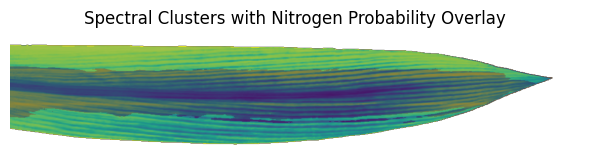

In [32]:
# Step 31: Spectral zones vs Nitrogen probability overlay

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

df = df_region
any_leaf = df['leaf'].unique()[0]
print("Analyzing leaf:", any_leaf)

raw_path = os.path.join(RAW_DIR, any_leaf + ".npz")
seg_path = os.path.join(SEG_DIR, any_leaf + ".npz")

raw = np.load(raw_path)
seg = np.load(seg_path)
cube = raw[raw.files[0]]
mask = seg['leaf_mask'] > 0
H, W, B = cube.shape

# Normalize per band
leaf_px = cube[mask]
leaf_px_scaled = scaler_model.transform(leaf_px)
leaf_pca_scores = PCA(n_components=3).fit_transform(leaf_px_scaled)

# KMeans on spectral PCs
K = 3
kmeans = KMeans(n_clusters=K, random_state=42)
cluster_ids = kmeans.fit_predict(leaf_pca_scores)
cluster_map = np.full((H,W), np.nan)
cluster_map[mask] = cluster_ids

# Nitrogen probability overlay (reuse pixel-level model)
leaf_px_scaled2 = scaler_model.transform(leaf_px)
leaf_pca_10 = pca_model.transform(leaf_px_scaled2)  # 364→10 PCs
pixel_probs = pixel_classifier.predict_proba(leaf_pca_10)[:,1]
prob_map = np.full((H,W), np.nan)
prob_map[mask] = pixel_probs

# Compute cluster-level mean nitrogen probability
cluster_n_results = {
    c: np.nanmean(prob_map[cluster_map == c])
    for c in range(K)
}
print("Cluster-level mean P(N2):", cluster_n_results)

# Plot
plt.figure(figsize=(6,5))
plt.imshow(cluster_map)
plt.imshow(prob_map, alpha=0.6)
plt.title("Spectral Clusters with Nitrogen Probability Overlay")
plt.axis('off')
plt.tight_layout()
plt.show()


## Step 32 - Side-by-side comparison of spectral clusters and nitrogen maps (N1 vs N2 leaf)

## Objective

Visually compare how spectral clusters and nitrogen probability patterns differ between a representative N1 leaf and a representative N2 leaf, shown side-by-side.

## Rationale

Earlier steps analyzed leaves in aggregate. This cell gives an intuitive, visual comparison between one low-nitrogen and one high-nitrogen leaf. By showing spectral clusters and P(N2) maps for both, you can demonstrate how nitrogen treatment changes both the spectral “zones” and the model’s nitrogen predictions.

## What this cell does

Selects one example N1 leaf and one example N2 leaf from the metadata table.
For each leaf:

Loads the hyperspectral cube and leaf mask.
Extracts leaf pixels and scales them using the same scaler as the pixel classifier.
Runs PCA (3 components) on pixel spectra for clustering.
Applies K-Means clustering (K = 3) to the 3D PC scores to get spectral clusters.
Builds a 2D cluster map where each pixel’s value is its cluster ID.
Uses the trained PCA model and pixel classifier to compute P(N2) for each pixel.
Builds a 2D nitrogen probability map for that leaf.
Computes and prints mean P(N2) per cluster, so you can see which spectral clusters are more N2-like.

Plots a 2 × 3 figure layout:

Row 1: N1 leaf
mid-band grayscale image
spectral cluster map (K = 3)
nitrogen probability map P(N2) with colorbar

Row 2: N2 leaf
mid-band grayscale image
spectral cluster map (K = 3)
nitrogen probability map P(N2) with colorbar

## Expected output

Console output listing, for each example leaf, the mean P(N2) for each spectral cluster.
A figure showing, for N1 and N2:

how clusters are distributed spatially in each leaf
how strongly nitrogen probability is expressed in each case

This makes it easy to visually argue that high-nitrogen leaves look more N2-like in the model’s output, and that certain clusters are more associated with N2.


Example N1 leaf: 22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-46_11-25-2021_14-53-36
Example N2 leaf: 22fieldcorn01fday2_27_1_na_1_2021-04-21-18-36-06_11-25-2021_16-31-27

Leaf 22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-46_11-25-2021_14-53-36 (N1) cluster mean P(N2): {0: 0.5698541997463452, 1: 0.729325652498784, 2: 0.7089763155532983}

Leaf 22fieldcorn01fday2_27_1_na_1_2021-04-21-18-36-06_11-25-2021_16-31-27 (N2) cluster mean P(N2): {0: 0.8127219268669665, 1: 0.8478198075885385, 2: 0.6572548533118164}


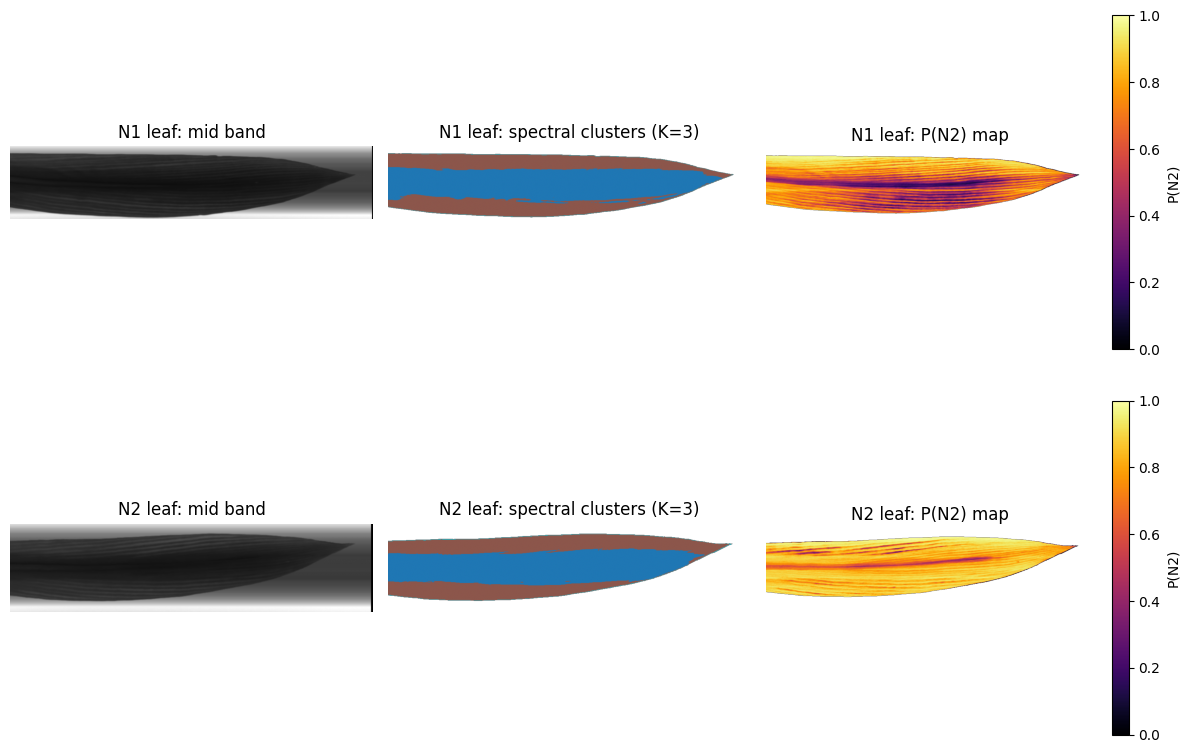

In [33]:
# Step 32: Compare spectral clusters + nitrogen probability
# for one N1 leaf vs one N2 leaf side-by-side

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Pick one N1 and one N2 leaf
leaf_N1 = gt[gt["treatment"] == "N1"]["file_name"].iloc[0]
leaf_N2 = gt[gt["treatment"] == "N2"]["file_name"].iloc[0]
print("Example N1 leaf:", leaf_N1)
print("Example N2 leaf:", leaf_N2)

example_leaves = [("N1", leaf_N1), ("N2", leaf_N2)]
K = 3  # number of clusters for KMeans

fig, axes = plt.subplots(len(example_leaves), 3, figsize=(12, 4 * len(example_leaves)))

if len(example_leaves) == 1:
    axes = np.expand_dims(axes, axis=0)

for i, (treat, leaf_name) in enumerate(example_leaves):
    raw_path = os.path.join(RAW_DIR, leaf_name + ".npz")
    seg_path = os.path.join(SEG_DIR, leaf_name + ".npz")

    raw = np.load(raw_path)
    seg = np.load(seg_path)

    cube = raw[raw.files[0]]           # (H, W, B)
    mask = seg["leaf_mask"] > 0
    H, W, B = cube.shape

    # --- Pixel spectra for this leaf ---
    leaf_px = cube[mask]

    # --- PCA for clustering (3 PCs) ---
    leaf_px_scaled = scaler_model.transform(leaf_px)
    leaf_pca_3 = PCA(n_components=3).fit_transform(leaf_px_scaled)

    # --- KMeans on spectral PCs ---
    kmeans = KMeans(n_clusters=K, random_state=42)
    cluster_ids = kmeans.fit_predict(leaf_pca_3)

    cluster_map = np.full((H, W), np.nan)
    cluster_map[mask] = cluster_ids

    # --- Nitrogen probability map using pixel-level model (10-PC classifier) ---
    leaf_pca_10 = pca_model.transform(leaf_px_scaled)
    pixel_probs = pixel_classifier.predict_proba(leaf_pca_10)[:, 1]

    prob_map = np.full((H, W), np.nan)
    prob_map[mask] = pixel_probs

    # --- Cluster-wise mean nitrogen probability ---
    cluster_means = {c: np.nanmean(prob_map[cluster_map == c]) for c in range(K)}
    print(f"\nLeaf {leaf_name} ({treat}) cluster mean P(N2):", cluster_means)

    # --- Plot: mid-band, clusters, prob map ---
    mid_band = B // 2

    ax0 = axes[i, 0]
    ax0.imshow(cube[:, :, mid_band], cmap="gray")
    ax0.set_title(f"{treat} leaf: mid band")
    ax0.axis("off")

    ax1 = axes[i, 1]
    im1 = ax1.imshow(cluster_map, cmap="tab10")
    ax1.set_title(f"{treat} leaf: spectral clusters (K={K})")
    ax1.axis("off")

    ax2 = axes[i, 2]
    im2 = ax2.imshow(prob_map, cmap="inferno", vmin=0, vmax=1)
    ax2.set_title(f"{treat} leaf: P(N2) map")
    ax2.axis("off")
    cb = plt.colorbar(im2, ax=ax2, fraction=0.046)
    cb.set_label("P(N2)")

plt.tight_layout()
plt.show()


## Step 33: Leaf Anatomical Region Analysis

## Goal

Analyze reflectance patterns and compute vegetation indices within anatomically segmented leaf regions.

## Why this matters

Different tissues within a corn leaf (veins, midrib, edges, and leaf tip) exhibit distinct hyperspectral responses. Extracting spectra and index statistics from these regions allows localized physiological interpretation instead of treating the leaf as a single uniform object.

## What this cell does

* Selects one leaf from the dataset
* Loads the hyperspectral reflectance cube and segmentation masks
* Generates wavelength vector using calibration formula
* Computes NDVI map using red and NIR bands
* Computes OCAR map using orange and red bands
* Applies named anatomical region masks
* Extracts pixel spectra from each region
* Computes mean spectrum, NDVI, and OCAR per region
* Generates:

  * Overlaid spectral curves per region
  * NDVI vs OCAR bar chart per region

## Expected output

* Pixel count per anatomical region
* Region-wise NDVI and OCAR values
* A clear spectral comparison plot for each tissue zone
* A bar plot comparing mean NDVI and OCAR for all leaf regions



Example leaf: 22fieldcorn01fday2_4_1_na_1_2021-04-21-15-56-46_11-25-2021_14-53-36
Image shape: (224, 1111, 364)
Leaf (all): 161904 pixels, NDVI=0.691, OCAR=0.325
Clean leaf: 115403 pixels, NDVI=0.713, OCAR=0.345
Veins: 38583 pixels, NDVI=0.711, OCAR=0.329
Midrib: 11510 pixels, NDVI=0.698, OCAR=0.275
Mesophyll: 123321 pixels, NDVI=0.685, OCAR=0.324
Leaf edge: 32804 pixels, NDVI=0.612, OCAR=0.275
Leaf tip: 6954 pixels, NDVI=0.608, OCAR=0.276


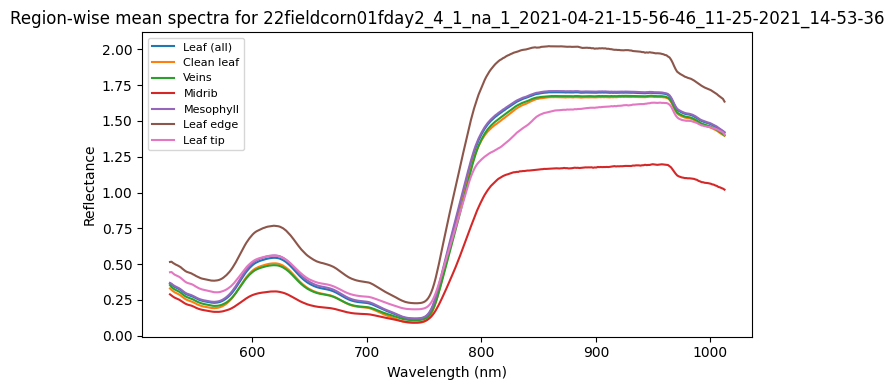

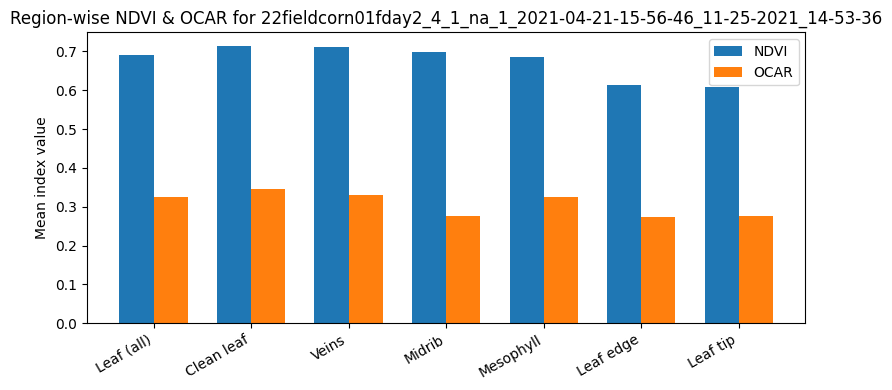

In [35]:
# Step 33: Region-wise spectra & indices using anatomical masks (leaf, vein, meso, edge, tip, etc.)

import numpy as np
import matplotlib.pyplot as plt
import os

# pick one example leaf
example_name = gt["file_name"].iloc[0]
print("Example leaf:", example_name)

# load cube + all masks
raw = np.load(os.path.join(RAW_DIR, example_name + ".npz"))
seg = np.load(os.path.join(SEG_DIR, example_name + ".npz"))

raw_img = raw[raw.files[0]]          # (H, W, B)
H, W, B = raw_img.shape
print("Image shape:", raw_img.shape)

# wavelengths (use global we already computed)
wavelengths = wavelengths_global

# ---- build NDVI & OCAR maps once ----
band_680 = np.argmin(np.abs(wavelengths - 680))
band_800 = np.argmin(np.abs(wavelengths - 800))
band_630 = np.argmin(np.abs(wavelengths - 630))

eps = 1e-8
red = raw_img[:, :, band_680].astype(float)
nir = raw_img[:, :, band_800].astype(float)
orange = raw_img[:, :, band_630].astype(float)

ndvi_map = (nir - red) / (nir + red + eps)
ocar_map = (orange - red) / (orange + red + eps)

# ---- define region masks + pretty names ----
region_masks = {
    "Leaf (all)":          seg["leaf_mask"]      > 0,
    "Clean leaf":          seg["cln_leaf_mask"]  > 0,
    "Veins":               seg["vein_mask"]      > 0,
    "Midrib":              seg["mrib_mask"]      > 0,
    "Mesophyll":           seg["meso_mask"]      > 0,
    "Leaf edge":           seg["leaf_edge_mask"] > 0,
    "Leaf tip":            seg["leaf_tip_mask"]  > 0,
}

region_stats = {}

for nice_name, m in region_masks.items():
    if m.sum() == 0:
        print(f"{nice_name}: 0 pixels, skipping")
        continue

    region_pixels = raw_img[m]   # (N_region, B)
    mean_spec = region_pixels.mean(axis=0)

    mean_ndvi = ndvi_map[m].mean()
    mean_ocar = ocar_map[m].mean()

    region_stats[nice_name] = {
        "mask": m,
        "mean_spectrum": mean_spec,
        "mean_ndvi": mean_ndvi,
        "mean_ocar": mean_ocar,
        "n_pixels": int(m.sum())
    }

    print(f"{nice_name}: {m.sum()} pixels, NDVI={mean_ndvi:.3f}, OCAR={mean_ocar:.3f}")

# ---- plot mean spectra for all regions ----
plt.figure(figsize=(7,4))
for name, stats in region_stats.items():
    plt.plot(wavelengths, stats["mean_spectrum"], label=name)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Reflectance")
plt.title(f"Region-wise mean spectra for {example_name}")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

# ---- bar plot of mean NDVI & OCAR by anatomical region ----
region_names = list(region_stats.keys())
mean_ndvi_vals = [region_stats[r]["mean_ndvi"] for r in region_names]
mean_ocar_vals = [region_stats[r]["mean_ocar"] for r in region_names]

x = np.arange(len(region_names))
width = 0.35

plt.figure(figsize=(8,4))
plt.bar(x - width/2, mean_ndvi_vals, width, label="NDVI")
plt.bar(x + width/2, mean_ocar_vals, width, label="OCAR")
plt.xticks(x, region_names, rotation=30, ha="right")
plt.ylabel("Mean index value")
plt.title(f"Region-wise NDVI & OCAR for {example_name}")
plt.legend()
plt.tight_layout()
plt.show()
